In [3]:
!pip -q install h5py numpy pandas matplotlib scipy scikit-learn seaborn

import os
import h5py
import json
import math
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import signal
from scipy.stats import pearsonr
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import (
    r2_score, mean_squared_error,
    accuracy_score, f1_score, roc_auc_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

plt.rcParams["figure.figsize"] = (12, 4)
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

In [4]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = "/content/drive/MyDrive/global_neurotech_hack_2026/medium_data"
h5_files = sorted(glob.glob(os.path.join(DATA_DIR, "*.h5")))
h5_files

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


['/content/drive/MyDrive/global_neurotech_hack_2026/medium_data/smoke_Ani_seed1.h5',
 '/content/drive/MyDrive/global_neurotech_hack_2026/medium_data/smoke_Ani_seed2.h5',
 '/content/drive/MyDrive/global_neurotech_hack_2026/medium_data/smoke_Ani_seed3.h5',
 '/content/drive/MyDrive/global_neurotech_hack_2026/medium_data/smoke_Ani_seed4.h5',
 '/content/drive/MyDrive/global_neurotech_hack_2026/medium_data/smoke_Ani_seed5.h5']

In [5]:
def print_h5_structure(h5_path: str):
    print(f"\n=== {os.path.basename(h5_path)} ===")
    with h5py.File(h5_path, "r") as f:
        def visitor(name, obj):
            if isinstance(obj, h5py.Dataset):
                print(f"[DATASET] {name:40s} shape={obj.shape} dtype={obj.dtype}")
            elif isinstance(obj, h5py.Group):
                print(f"[GROUP]   {name}")
        f.visititems(visitor)

for path in h5_files:
    print_h5_structure(path)

def find_candidate_datasets(h5_path: str):
    candidates = []
    with h5py.File(h5_path, "r") as f:
        def visitor(name, obj):
            if isinstance(obj, h5py.Dataset):
                shape = obj.shape
                dtype = obj.dtype
                if np.issubdtype(dtype, np.number):
                    candidates.append((name, shape, dtype))
        f.visititems(visitor)
    return candidates

for path in h5_files:
    print(f"\n=== Candidates in {os.path.basename(path)} ===")
    candidates = find_candidate_datasets(path)
    for name, shape, dtype in candidates:
        print(f"{name:40s} shape={shape} dtype={dtype}")


=== smoke_Ani_seed1.h5 ===
[GROUP]   acquisition
[DATASET] acquisition/ElectricalSeries             shape=(509276000,) dtype=int32
[DATASET] acquisition/sequence_number              shape=(6701000,) dtype=uint64
[DATASET] acquisition/timestamp_ns                 shape=(6701000,) dtype=uint64
[DATASET] acquisition/unix_timestamp_ns            shape=(6701000,) dtype=uint64
[GROUP]   general
[GROUP]   general/device
[GROUP]   general/extracellular_ephys
[GROUP]   general/extracellular_ephys/electrodes
[DATASET] general/extracellular_ephys/electrodes/id shape=(76,) dtype=uint32

=== smoke_Ani_seed2.h5 ===
[GROUP]   acquisition
[DATASET] acquisition/ElectricalSeries             shape=(335705984,) dtype=int32
[DATASET] acquisition/sequence_number              shape=(4417184,) dtype=uint64
[DATASET] acquisition/timestamp_ns                 shape=(4417184,) dtype=uint64
[DATASET] acquisition/unix_timestamp_ns            shape=(4417184,) dtype=uint64
[GROUP]   general
[GROUP]   general/device


In [6]:
DATASET_KEY = "acquisition/ElectricalSeries"
FS = 32000
ENCODED_CHANNELS = 64
GT_CHANNELS = 12
TOTAL_CHANNELS = 76

def load_h5_array(h5_path: str, dataset_key: str, expected_channels: int = 76):
    with h5py.File(h5_path, "r") as f:
        arr = np.array(f[dataset_key])

    print("Raw loaded shape:", arr.shape, "dtype:", arr.dtype)

    if arr.ndim == 1:
        if arr.shape[0] % expected_channels != 0:
            raise ValueError(
                f"1D array length {arr.shape[0]} is not divisible by expected_channels={expected_channels}"
            )
        data = arr.reshape(-1, expected_channels)

    elif arr.ndim == 2:
        if arr.shape[1] == expected_channels:
            data = arr
        elif arr.shape[0] == expected_channels:
            data = arr.T
        else:
            raise ValueError(
                f"Could not infer channel dimension. Shape={arr.shape}, expected one dim to equal {expected_channels}"
            )
    else:
        raise ValueError(f"Expected 1D or 2D array, got shape {arr.shape}")

    print("Using shape (T, C):", data.shape)
    return data

all_data = []
for path in h5_files:
    data = load_h5_array(path, DATASET_KEY, expected_channels=TOTAL_CHANNELS)
    all_data.append((path, data))

Raw loaded shape: (509276000,) dtype: int32
Using shape (T, C): (6701000, 76)
Raw loaded shape: (335705984,) dtype: int32
Using shape (T, C): (4417184, 76)
Raw loaded shape: (330238848,) dtype: int32
Using shape (T, C): (4345248, 76)
Raw loaded shape: (335669504,) dtype: int32
Using shape (T, C): (4416704, 76)
Raw loaded shape: (326223616,) dtype: int32
Using shape (T, C): (4292416, 76)


In [7]:
def split_channels(data: np.ndarray):
    X = data[:, :ENCODED_CHANNELS]
    Y = data[:, ENCODED_CHANNELS:ENCODED_CHANNELS + GT_CHANNELS]
    return X, Y

for path, data in all_data:
    X, Y = split_channels(data)
    print(os.path.basename(path), "X:", X.shape, "Y:", Y.shape)

smoke_Ani_seed1.h5 X: (6701000, 64) Y: (6701000, 12)
smoke_Ani_seed2.h5 X: (4417184, 64) Y: (4417184, 12)
smoke_Ani_seed3.h5 X: (4345248, 64) Y: (4345248, 12)
smoke_Ani_seed4.h5 X: (4416704, 64) Y: (4416704, 12)
smoke_Ani_seed5.h5 X: (4292416, 64) Y: (4292416, 12)


In [8]:
def summarize_channels(arr: np.ndarray, prefix: str):
    rows = []
    for ch in range(arr.shape[1]):
        vals = arr[:, ch]
        uniq = np.unique(vals[: min(len(vals), 200000)])  # avoid huge memory
        rows.append({
            "channel": f"{prefix}{ch}",
            "min": float(np.min(vals)),
            "max": float(np.max(vals)),
            "mean": float(np.mean(vals)),
            "std": float(np.std(vals)),
            "n_unique_sampled": int(len(uniq)),
            "frac_zero": float(np.mean(vals == 0)),
        })
    return pd.DataFrame(rows)

for path, data in all_data:
    X, Y = split_channels(data)
    print(f"\n=== {os.path.basename(path)}: Encoded summary ===")
    display(summarize_channels(X, "enc_"))
    print(f"\n=== {os.path.basename(path)}: Ground-truth summary ===")
    display(summarize_channels(Y, "gt_"))


=== smoke_Ani_seed1.h5: Encoded summary ===


,channel,min,max,mean,std,n_unique_sampled,frac_zero
0,enc_0,-1110.0,171.0,-0.257271,40.151721,368,0.017999
1,enc_1,-887.0,160.0,-0.265467,40.187123,412,0.017915
2,enc_2,-888.0,169.0,-0.250431,40.182806,368,0.017863
3,enc_3,-917.0,161.0,-0.274128,40.203162,400,0.017908
4,enc_4,-897.0,175.0,-0.213512,40.073491,392,0.017889
...,...,...,...,...,...,...,...
59,enc_59,-888.0,155.0,-0.272635,40.227791,424,0.017865
60,enc_60,-895.0,163.0,-0.254379,40.157461,407,0.017842
61,enc_61,-906.0,157.0,-0.281688,40.229338,411,0.017916
62,enc_62,-892.0,168.0,-0.251100,40.176469,488,0.018031



=== smoke_Ani_seed1.h5: Ground-truth summary ===


,channel,min,max,mean,std,n_unique_sampled,frac_zero
0,gt_0,-32767.0,32767.0,-50.251475,3334.498086,1,0.000000
1,gt_1,-32767.0,32767.0,87.717320,3845.091335,1,0.000000
2,gt_2,-32767.0,32767.0,-180.869501,4073.871829,1,0.000000
3,gt_3,-32767.0,32767.0,70.053730,4362.720307,1,0.000000
4,gt_4,0.0,32767.0,52.888803,1315.374546,1,0.998386
5,gt_5,0.0,32767.0,220.317856,2677.800445,1,0.993276
6,gt_6,0.0,32767.0,263.974590,2929.159062,1,0.991944
7,gt_7,0.0,32767.0,113.757870,1927.320233,1,0.996528
8,gt_8,0.0,32767.0,473.182668,3909.075931,2,0.985559
9,gt_9,0.0,32767.0,235.339528,2766.945177,1,0.992818



=== smoke_Ani_seed2.h5: Encoded summary ===


,channel,min,max,mean,std,n_unique_sampled,frac_zero
0,enc_0,-894.0,165.0,-0.240121,40.093253,377,0.017921
1,enc_1,-894.0,158.0,-0.277312,40.157565,406,0.017998
2,enc_2,-890.0,162.0,-0.249109,40.150782,395,0.017947
3,enc_3,-869.0,170.0,-0.261381,40.163666,380,0.017974
4,enc_4,-889.0,159.0,-0.233969,40.099149,400,0.018008
...,...,...,...,...,...,...,...
59,enc_59,-886.0,156.0,-0.288743,40.202279,427,0.017904
60,enc_60,-873.0,165.0,-0.257637,40.120002,402,0.018061
61,enc_61,-870.0,160.0,-0.292435,40.271741,419,0.017879
62,enc_62,-893.0,172.0,-0.256695,40.135643,453,0.017937


... (10 outputs left out)


=== smoke_Ani_seed5.h5: Encoded summary ===


,channel,min,max,mean,std,n_unique_sampled,frac_zero
0,enc_0,-899.0,154.0,-0.270167,40.287151,391,0.017934
1,enc_1,-899.0,161.0,-0.279784,40.232753,397,0.017897
2,enc_2,-887.0,166.0,-0.291934,40.257494,371,0.017938
3,enc_3,-892.0,171.0,-0.277711,40.211676,405,0.018029
4,enc_4,-878.0,167.0,-0.247885,40.152419,367,0.017932
...,...,...,...,...,...,...,...
59,enc_59,-878.0,162.0,-0.264026,40.247259,390,0.017919
60,enc_60,-891.0,158.0,-0.291138,40.296906,460,0.017991
61,enc_61,-886.0,161.0,-0.324054,40.385919,403,0.017977
62,enc_62,-907.0,165.0,-0.235225,40.165612,383,0.017898



=== smoke_Ani_seed5.h5: Ground-truth summary ===


,channel,min,max,mean,std,n_unique_sampled,frac_zero
0,gt_0,-32767.0,32767.0,-100.810427,5441.729095,1,0.000000
1,gt_1,-32767.0,32767.0,-193.769357,4342.850814,1,0.000000
2,gt_2,-32767.0,32767.0,157.648414,4748.565104,1,0.000000
3,gt_3,-32767.0,32767.0,-77.179509,4626.975696,1,0.000000
4,gt_4,0.0,32767.0,241.346941,2801.779234,1,0.992634
5,gt_5,0.0,32767.0,306.813520,3155.823836,1,0.990637
6,gt_6,0.0,32767.0,111.146618,1905.147672,1,0.996608
7,gt_7,0.0,32767.0,100.398373,1810.986931,1,0.996936
8,gt_8,0.0,32767.0,298.508059,3113.214818,1,0.990890
9,gt_9,0.0,32767.0,717.445310,4795.185367,2,0.978105



=== GT traces: smoke_Ani_seed1.h5 ===


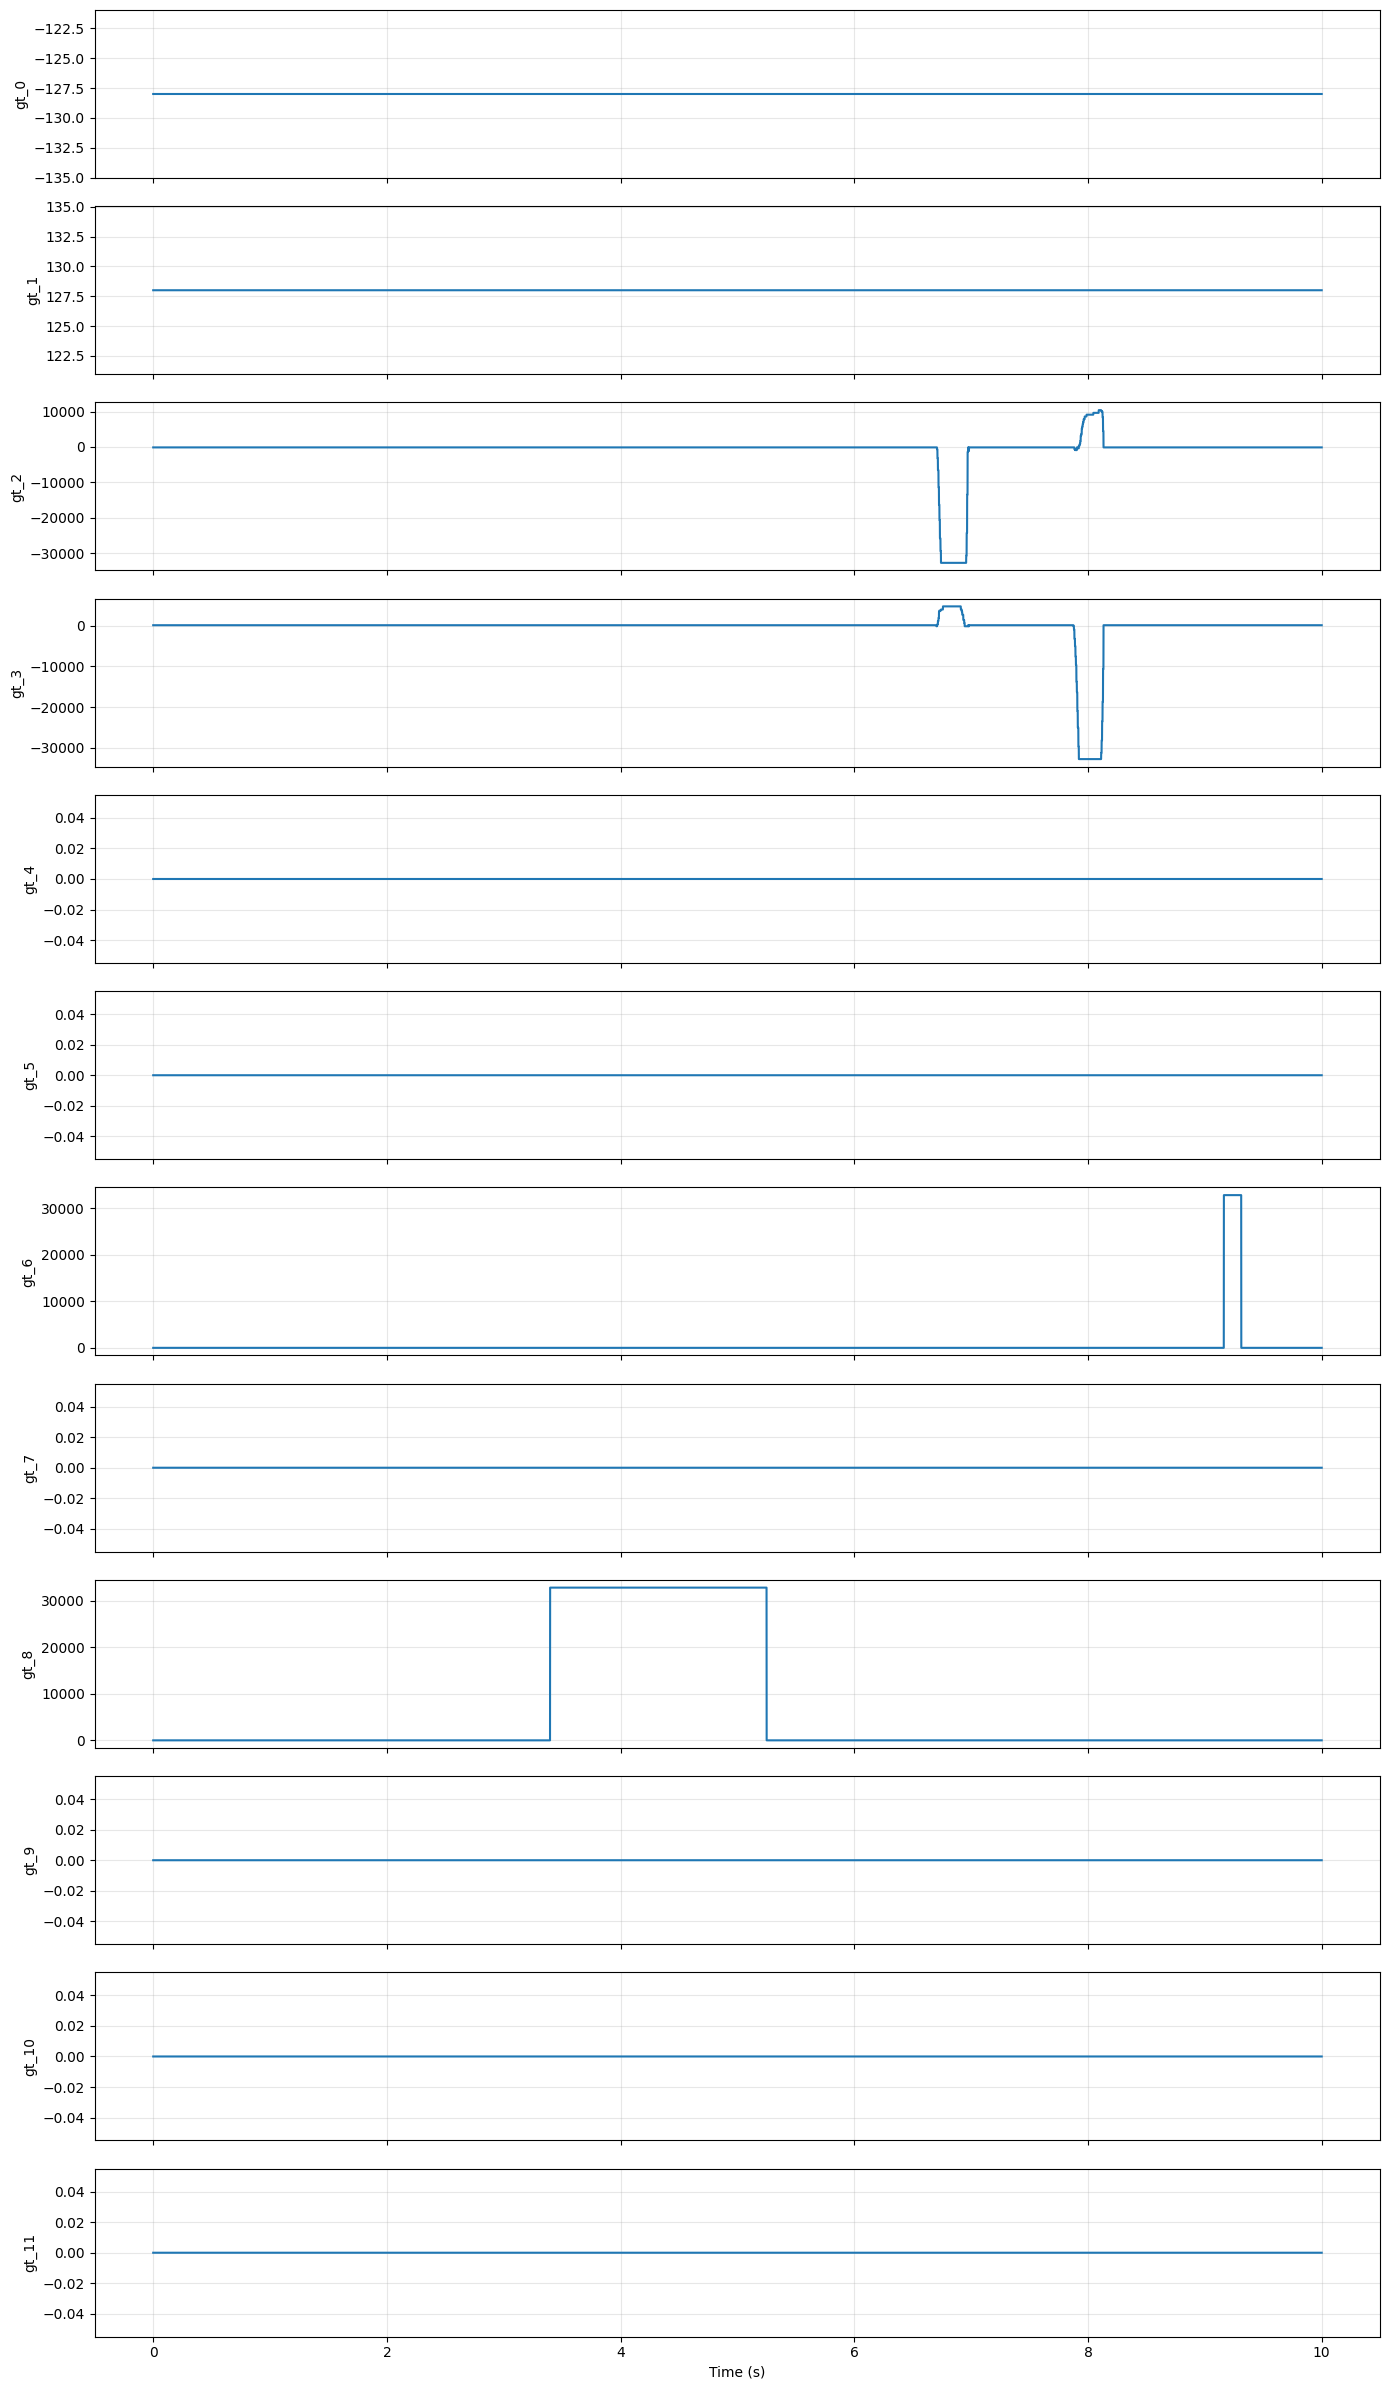


=== GT traces: smoke_Ani_seed2.h5 ===


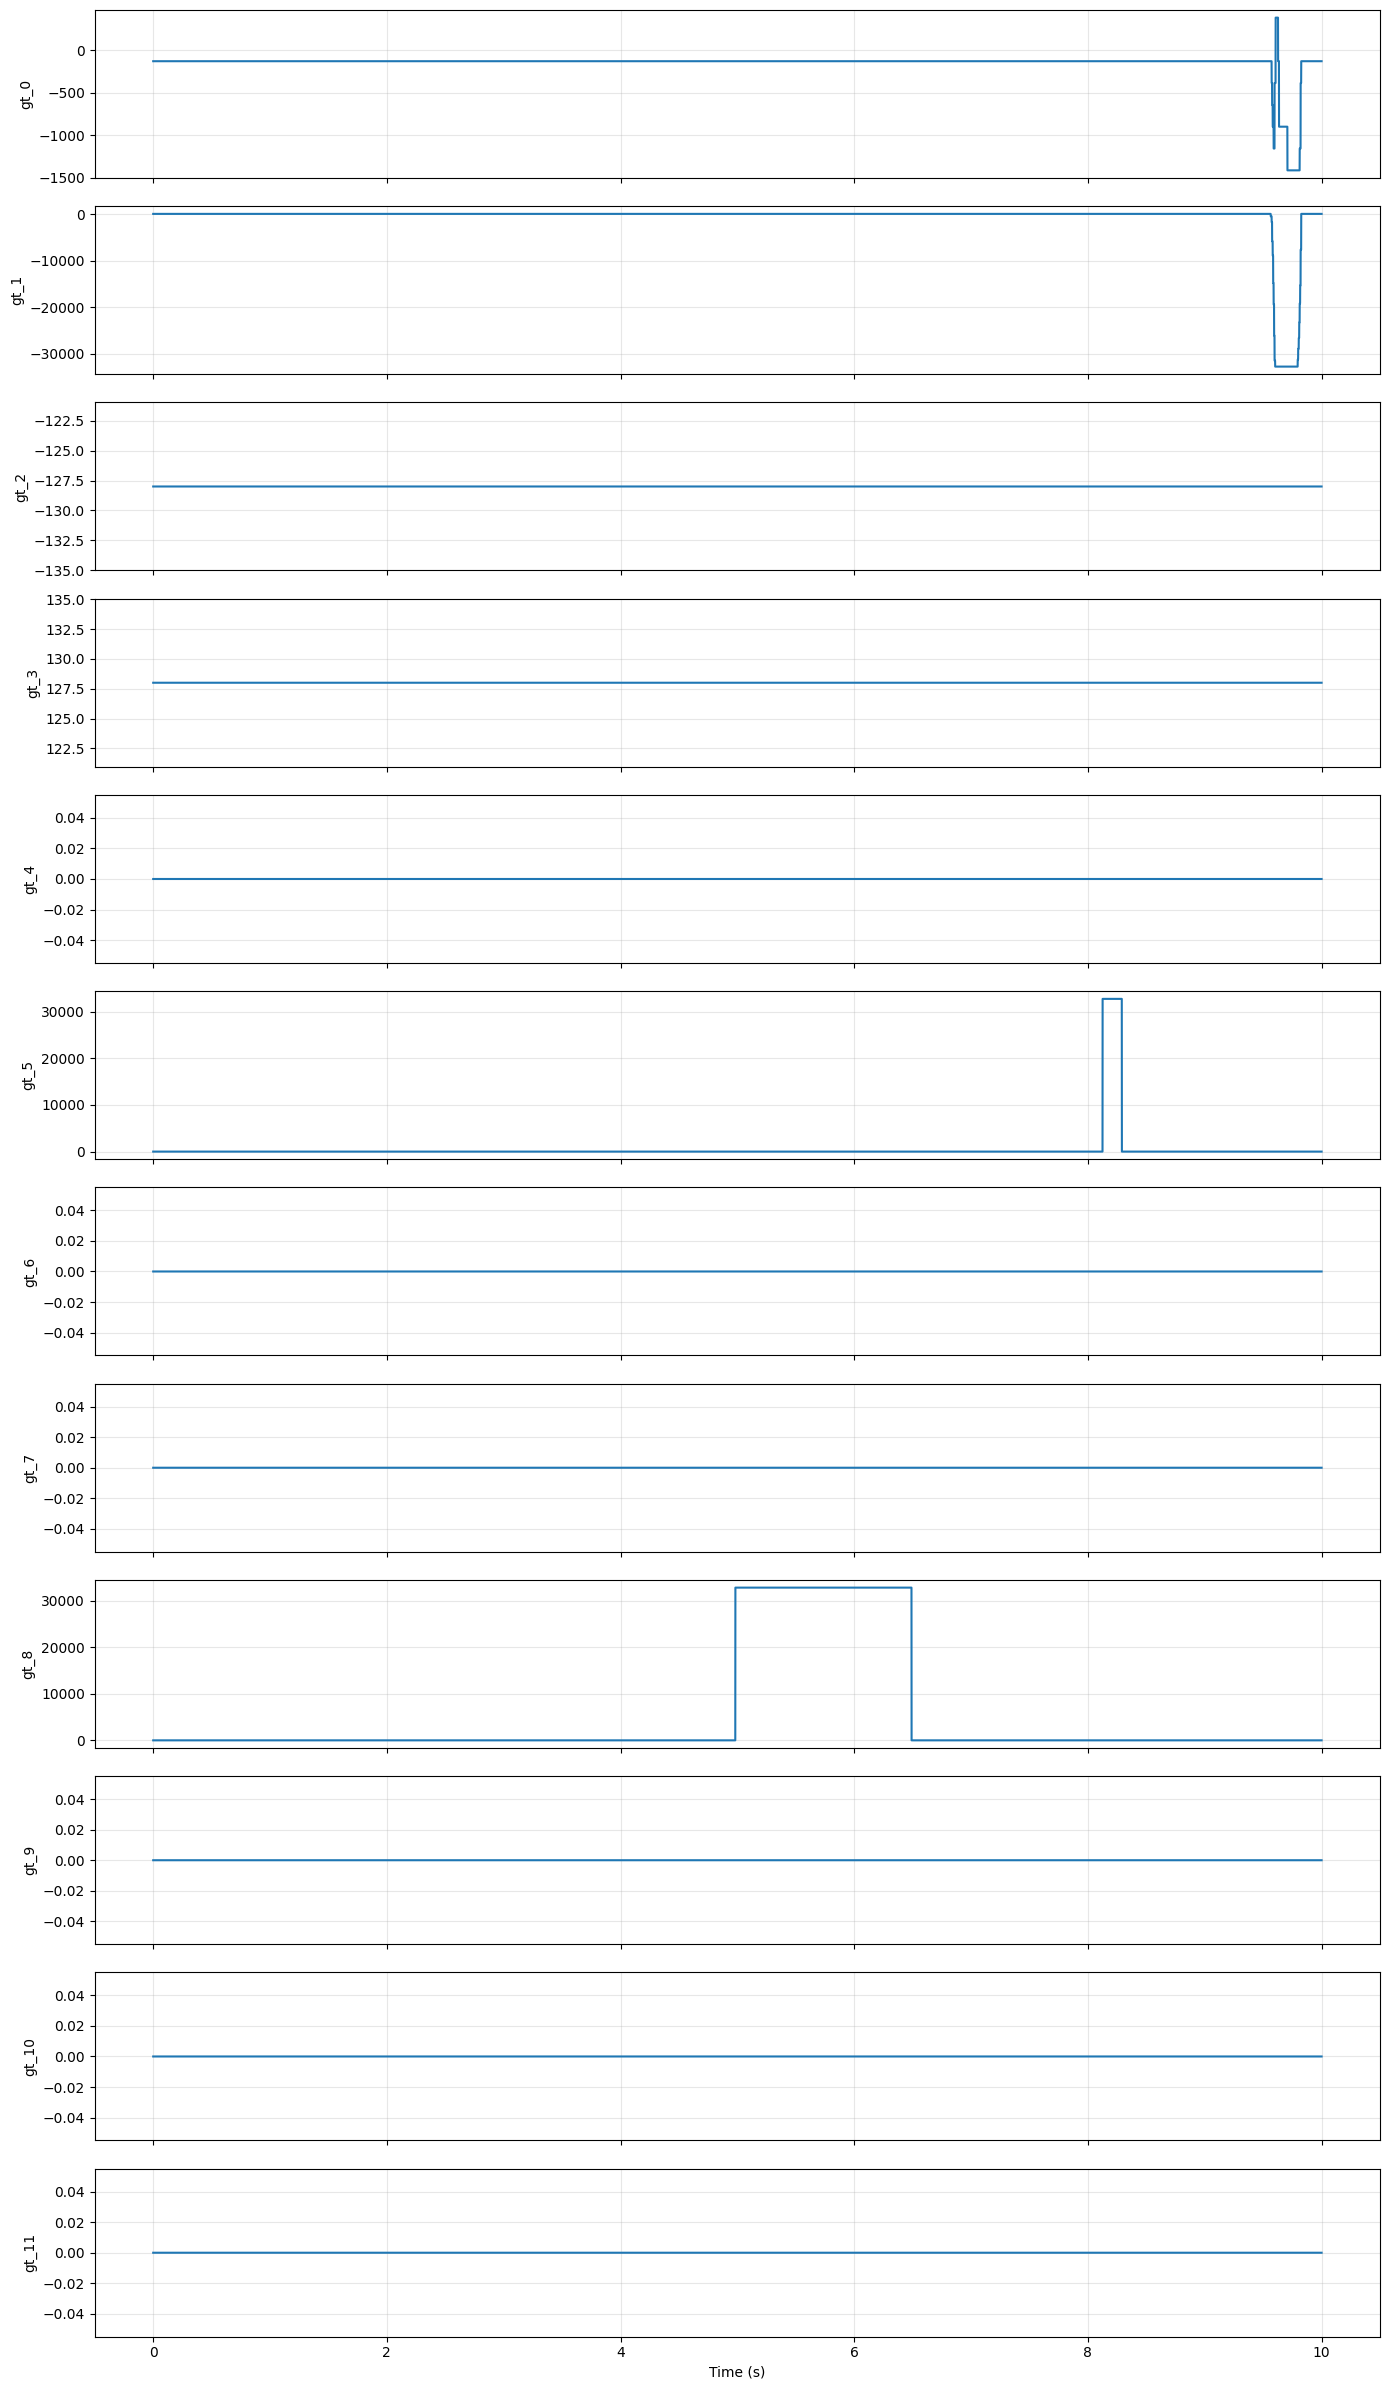


=== GT traces: smoke_Ani_seed3.h5 ===


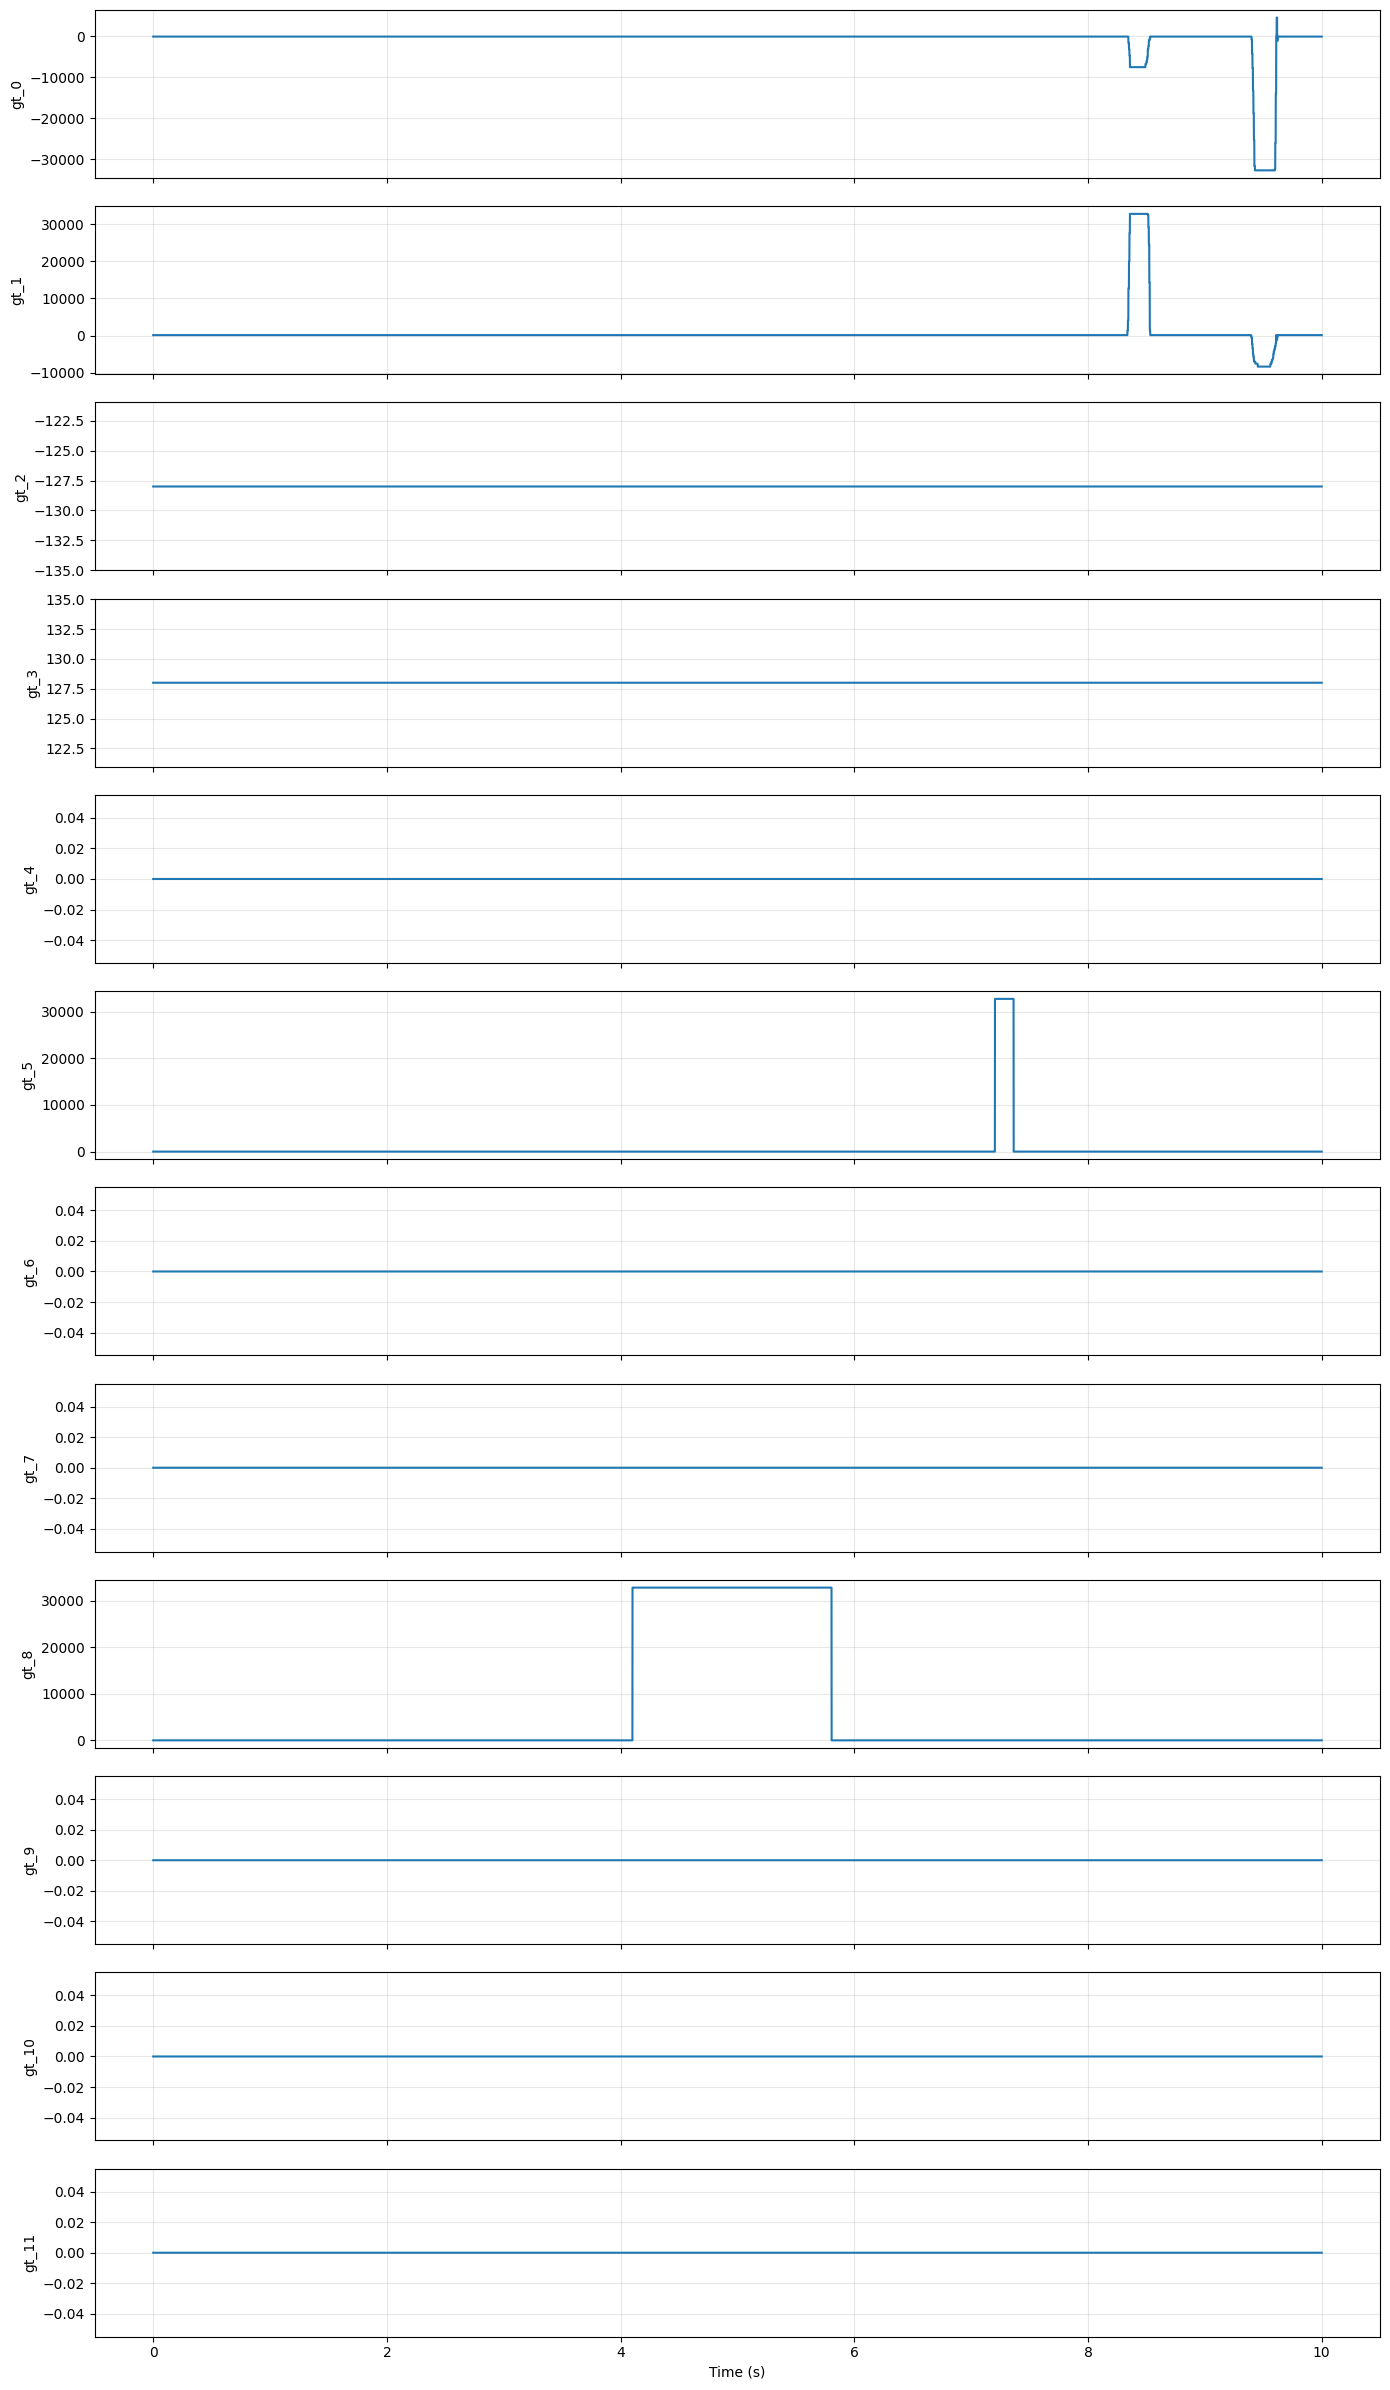


=== GT traces: smoke_Ani_seed4.h5 ===


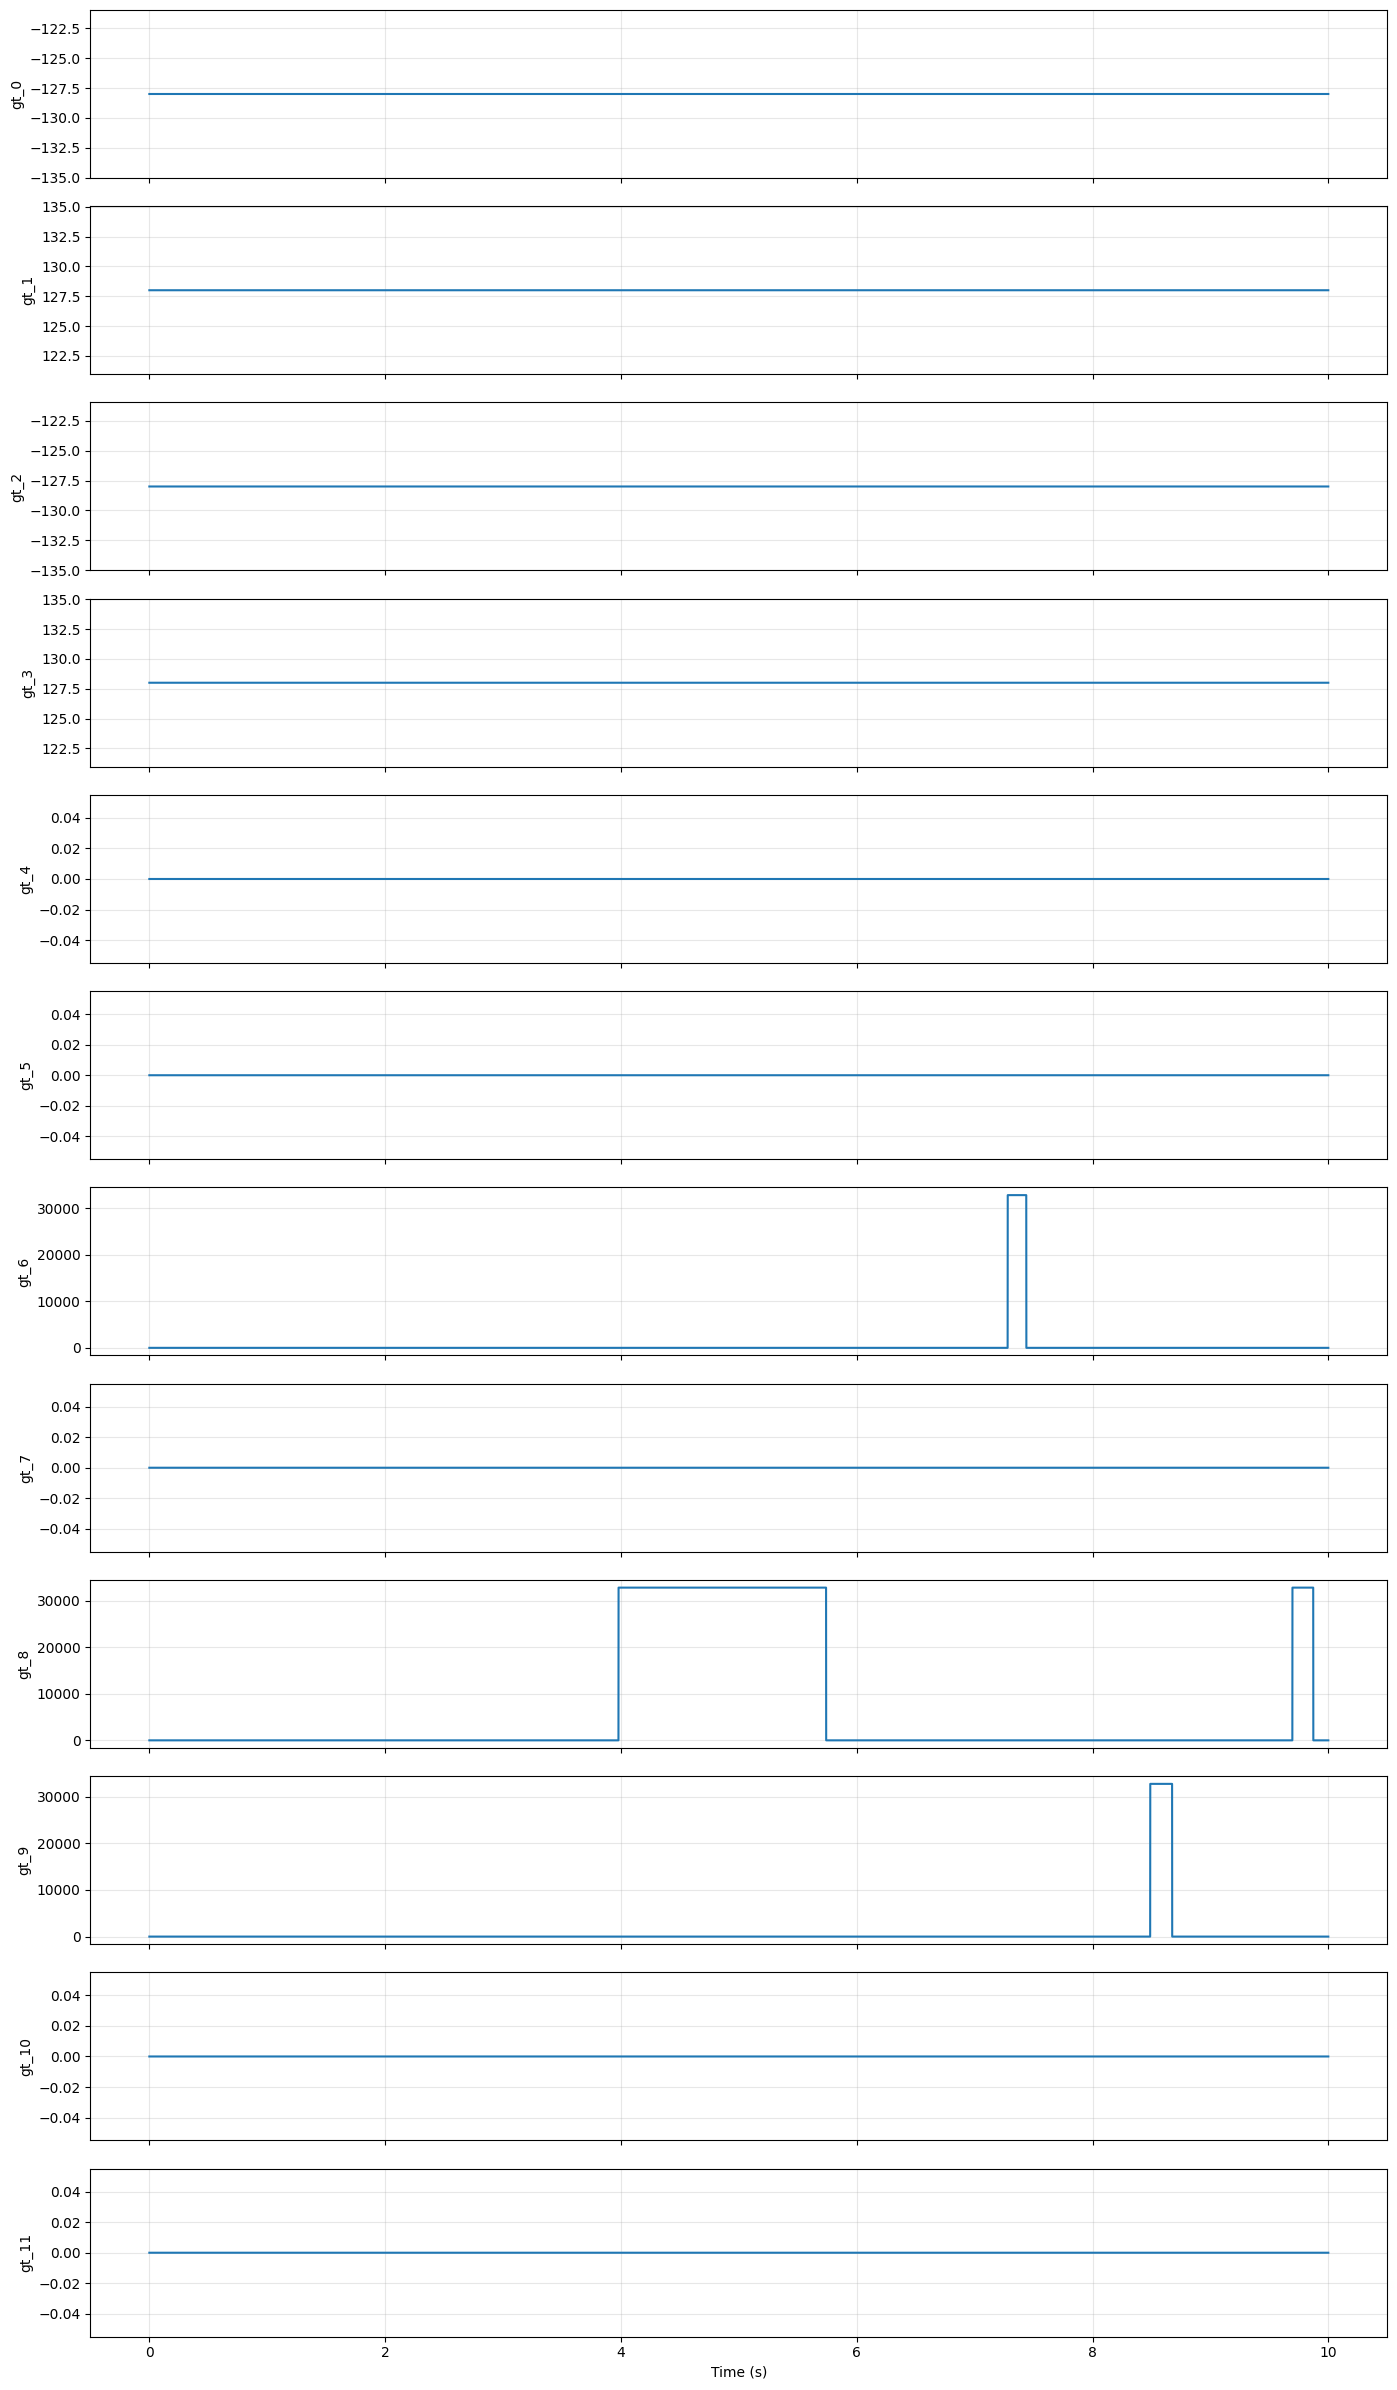


=== GT traces: smoke_Ani_seed5.h5 ===


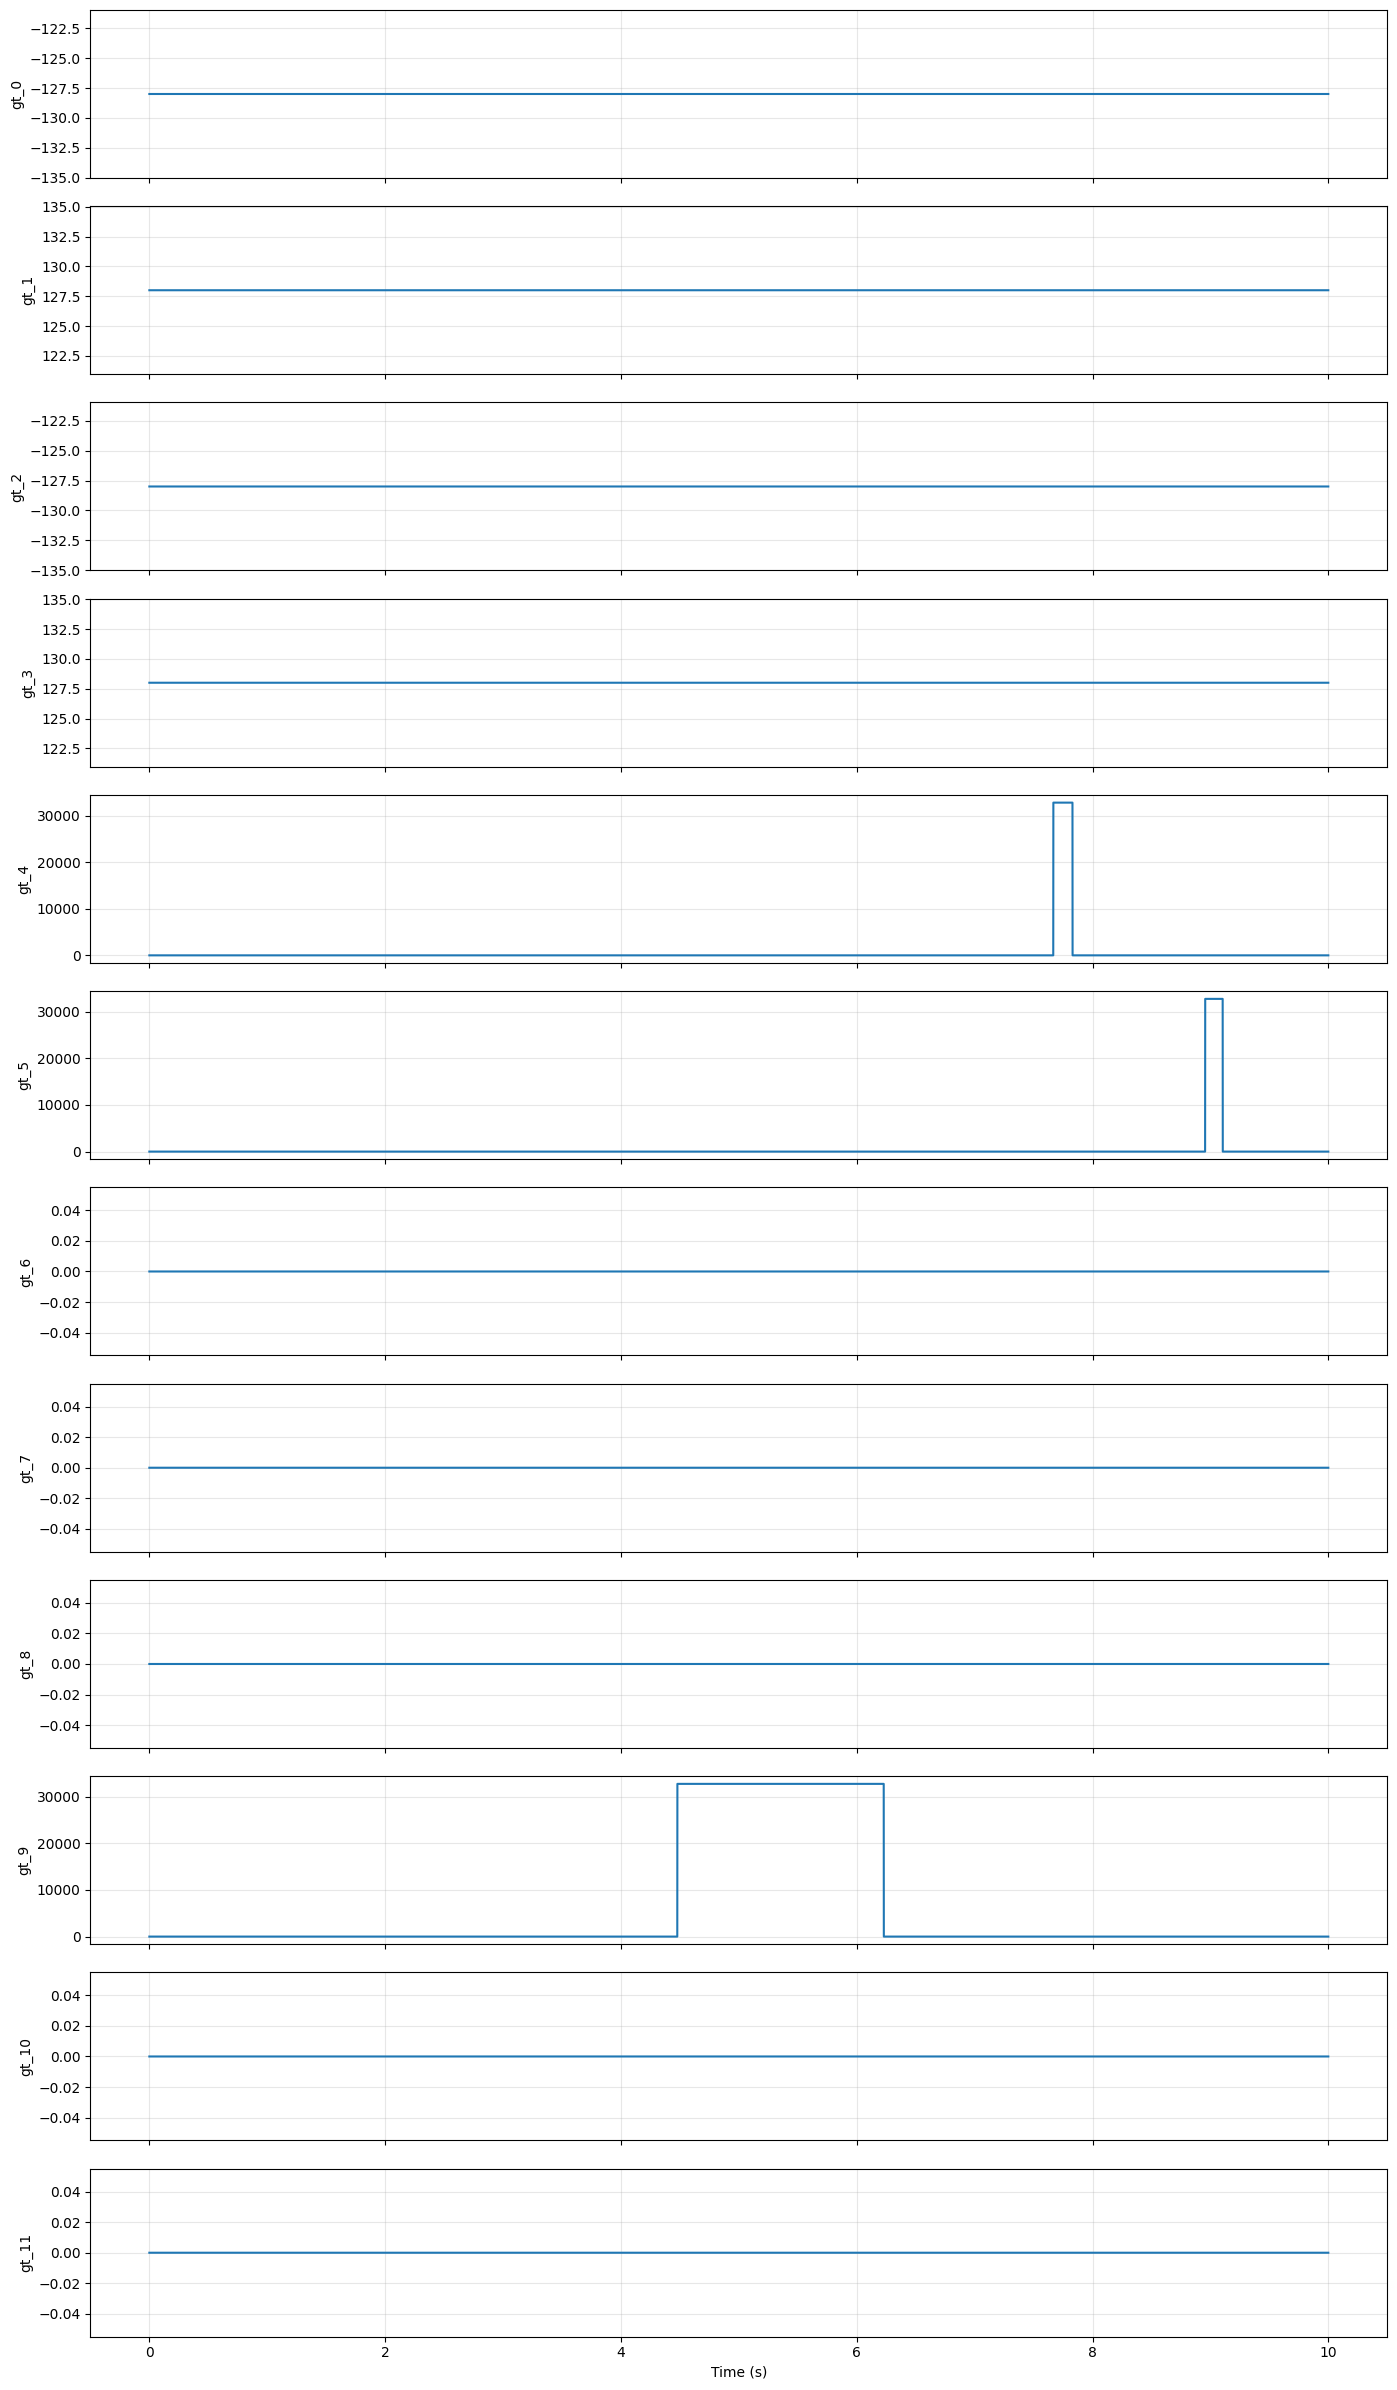

In [9]:
def plot_ground_truths(Y: np.ndarray, fs: int, seconds: float = 10.0, start_sec: float = 0.0):
    start = int(start_sec * fs)
    end = min(len(Y), int((start_sec + seconds) * fs))
    t = np.arange(start, end) / fs

    fig, axes = plt.subplots(GT_CHANNELS, 1, figsize=(14, 2 * GT_CHANNELS), sharex=True)
    if GT_CHANNELS == 1:
        axes = [axes]

    for ch in range(GT_CHANNELS):
        axes[ch].plot(t, Y[start:end, ch])
        axes[ch].set_ylabel(f"gt_{ch}")
        axes[ch].grid(True, alpha=0.3)

    axes[-1].set_xlabel("Time (s)")
    plt.tight_layout()
    plt.show()

for path, data in all_data:
    _, Y = split_channels(data)
    print(f"\n=== GT traces: {os.path.basename(path)} ===")
    plot_ground_truths(Y, FS, seconds=10, start_sec=0)


=== Encoded heatmap: smoke_Ani_seed1.h5 ===


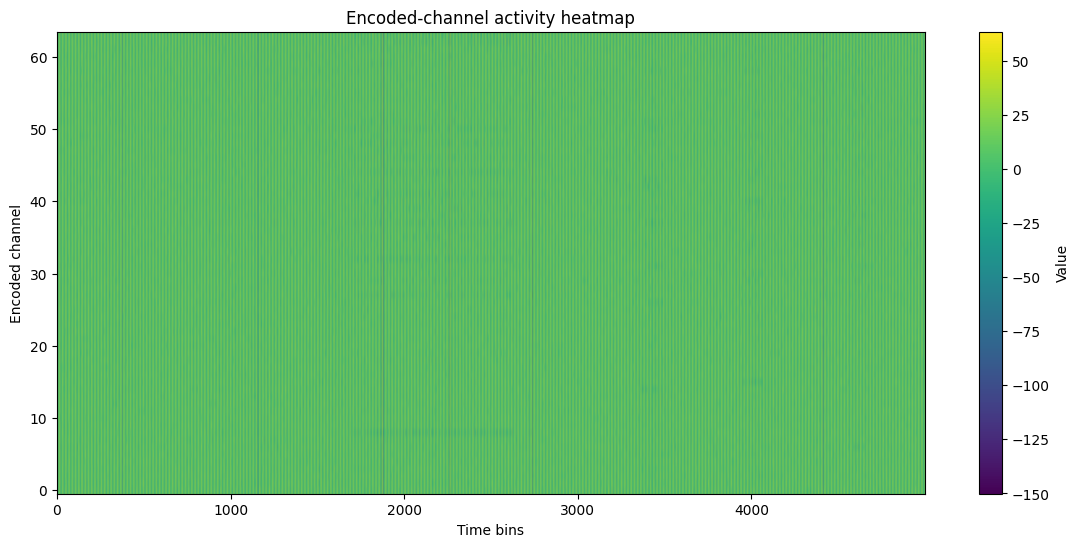


=== Encoded heatmap: smoke_Ani_seed2.h5 ===


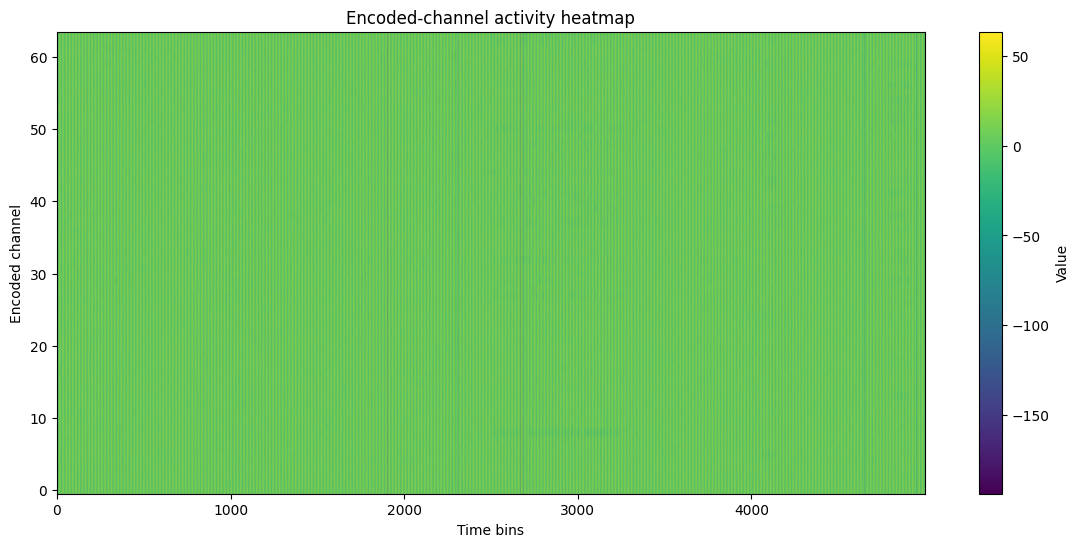


=== Encoded heatmap: smoke_Ani_seed3.h5 ===


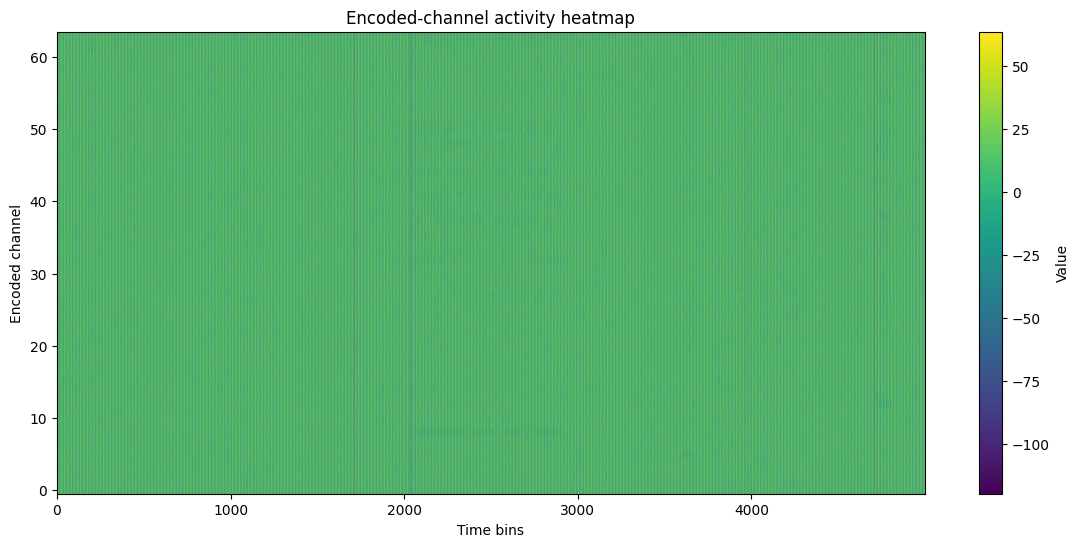


=== Encoded heatmap: smoke_Ani_seed4.h5 ===


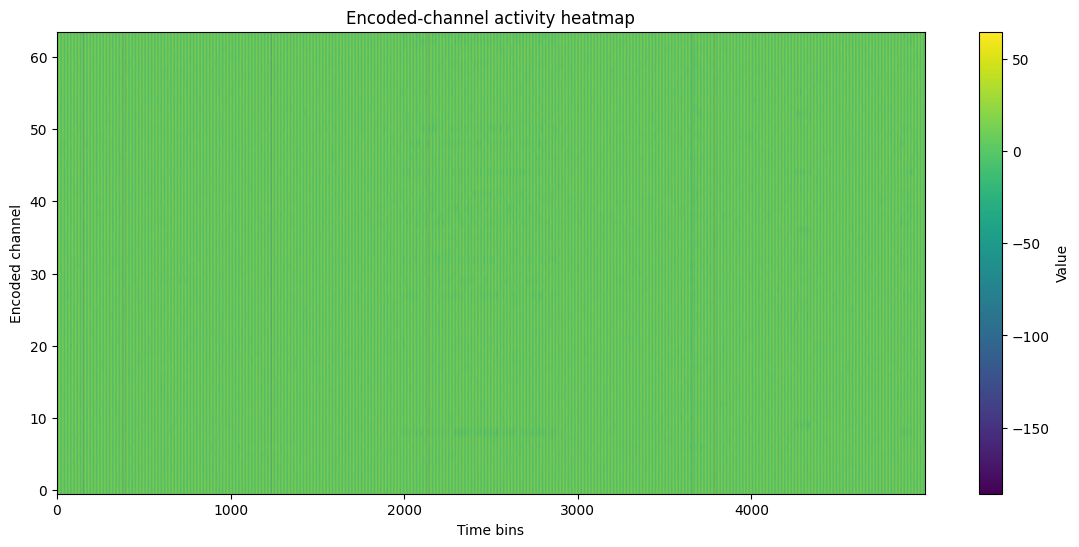


=== Encoded heatmap: smoke_Ani_seed5.h5 ===


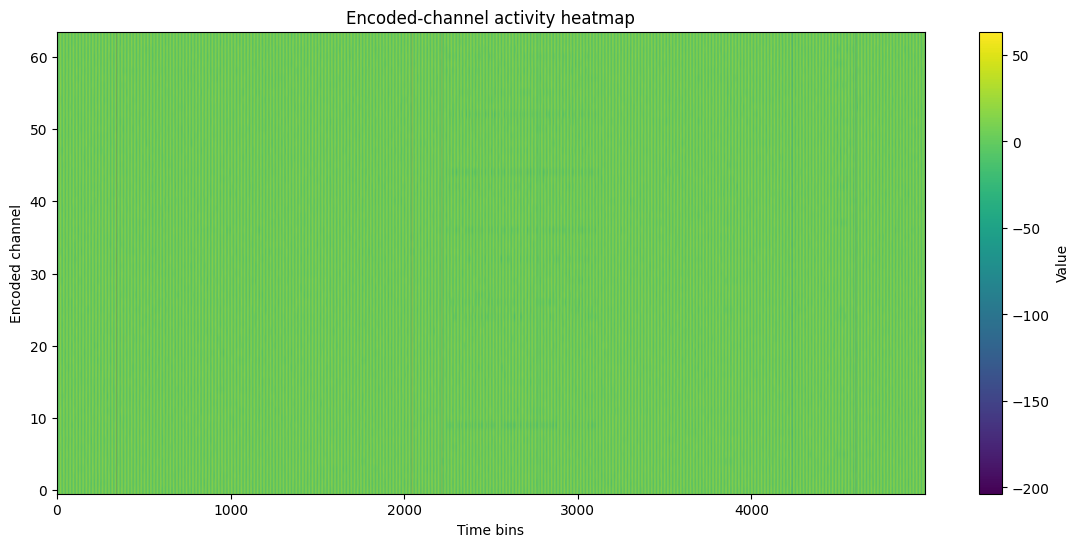

In [10]:
def plot_encoded_heatmap(X: np.ndarray, fs: int, seconds: float = 10.0, start_sec: float = 0.0, downsample: int = 32):
    start = int(start_sec * fs)
    end = min(len(X), int((start_sec + seconds) * fs))
    seg = X[start:end]

    if downsample > 1:
        usable = (len(seg) // downsample) * downsample
        seg = seg[:usable].reshape(-1, downsample, X.shape[1]).mean(axis=1)

    plt.figure(figsize=(14, 6))
    plt.imshow(seg.T, aspect='auto', origin='lower')
    plt.colorbar(label="Value")
    plt.ylabel("Encoded channel")
    plt.xlabel("Time bins")
    plt.title("Encoded-channel activity heatmap")
    plt.show()

for path, data in all_data:
    X, _ = split_channels(data)
    print(f"\n=== Encoded heatmap: {os.path.basename(path)} ===")
    plot_encoded_heatmap(X, FS, seconds=10, start_sec=0, downsample=64)


=== Encoded correlation matrix: smoke_Ani_seed1.h5 ===


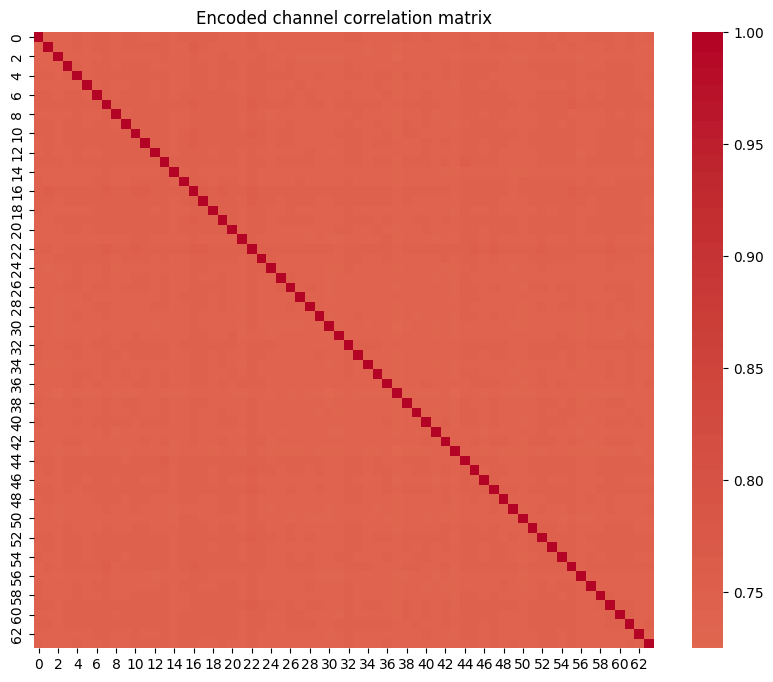


=== Encoded correlation matrix: smoke_Ani_seed2.h5 ===


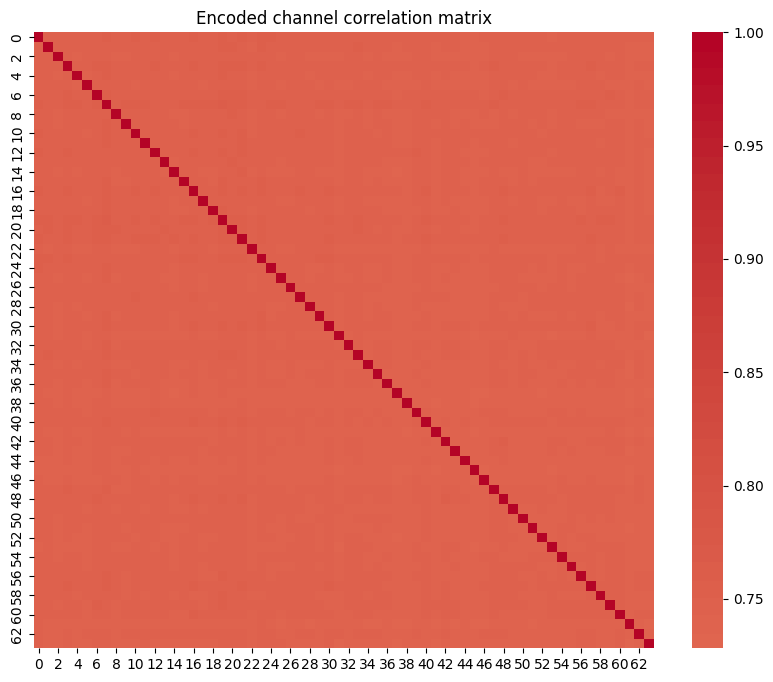


=== Encoded correlation matrix: smoke_Ani_seed3.h5 ===


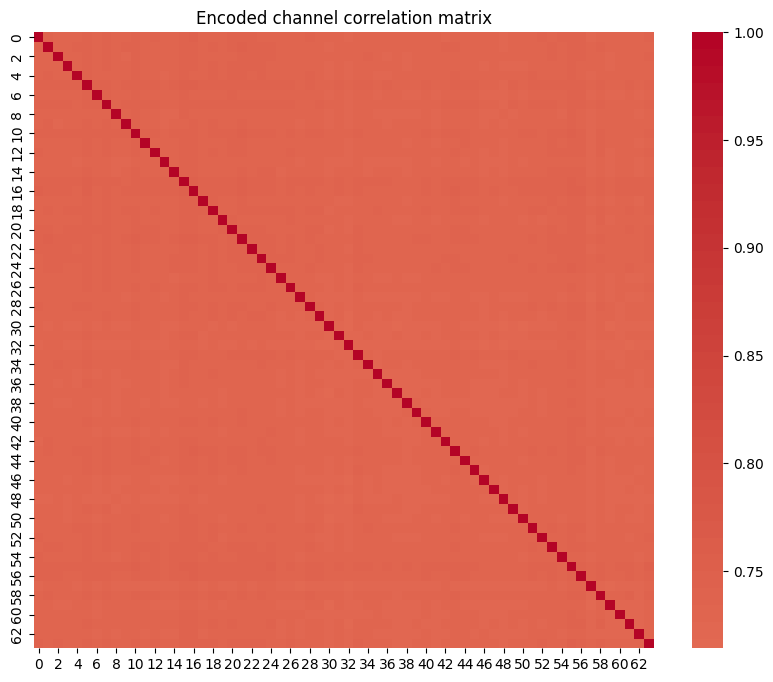


=== Encoded correlation matrix: smoke_Ani_seed4.h5 ===


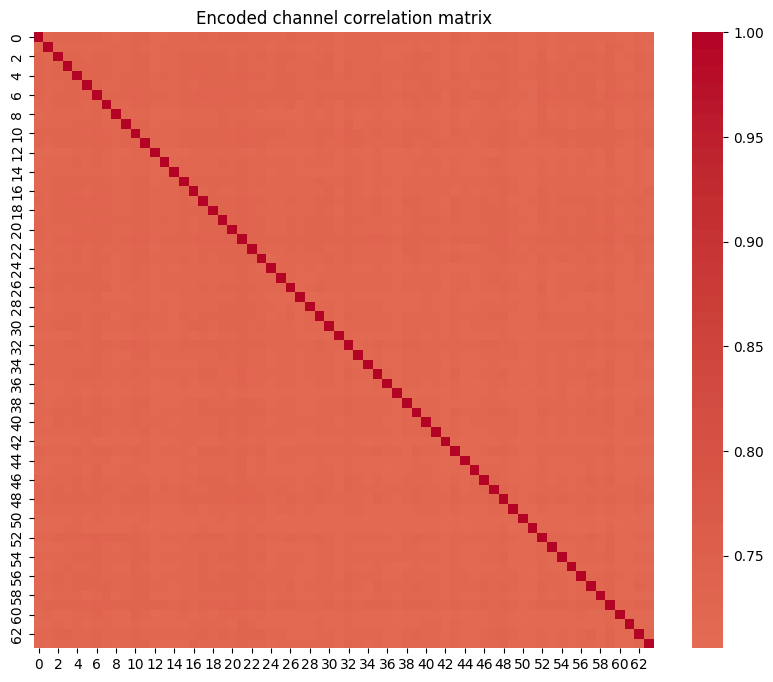


=== Encoded correlation matrix: smoke_Ani_seed5.h5 ===


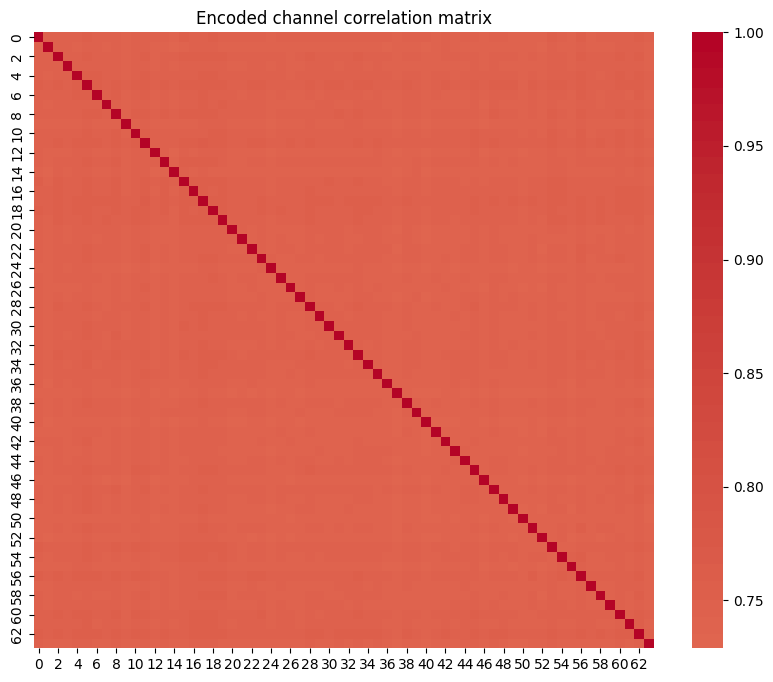

In [11]:
def plot_encoded_corr(X: np.ndarray, max_points: int = 20000):
    if len(X) > max_points:
        idx = np.linspace(0, len(X) - 1, max_points).astype(int)
        Xs = X[idx]
    else:
        Xs = X

    corr = np.corrcoef(Xs.T)
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, cmap="coolwarm", center=0)
    plt.title("Encoded channel correlation matrix")
    plt.show()

for path, data in all_data:
    X, _ = split_channels(data)
    print(f"\n=== Encoded correlation matrix: {os.path.basename(path)} ===")
    plot_encoded_corr(X)

In [12]:
def classify_gt_channels(Y: np.ndarray):
    rows = []
    for ch in range(Y.shape[1]):
        vals = Y[:, ch]
        uniq = np.unique(vals[: min(len(vals), 200000)])
        nuniq = len(uniq)

        # crude heuristic
        is_binaryish = (
            nuniq <= 4 and
            np.all(np.isfinite(vals))
        )

        rows.append({
            "gt_channel": ch,
            "min": float(vals.min()),
            "max": float(vals.max()),
            "std": float(vals.std()),
            "n_unique_sampled": nuniq,
            "binaryish_guess": bool(is_binaryish),
        })
    return pd.DataFrame(rows)

for path, data in all_data:
    _, Y = split_channels(data)
    print(f"\n=== GT type guesses: {os.path.basename(path)} ===")
    display(classify_gt_channels(Y))


=== GT type guesses: smoke_Ani_seed1.h5 ===


,gt_channel,min,max,std,n_unique_sampled,binaryish_guess
0,0,-32767.0,32767.0,3334.498086,1,True
1,1,-32767.0,32767.0,3845.091335,1,True
2,2,-32767.0,32767.0,4073.871829,1,True
3,3,-32767.0,32767.0,4362.720307,1,True
4,4,0.0,32767.0,1315.374546,1,True
5,5,0.0,32767.0,2677.800445,1,True
6,6,0.0,32767.0,2929.159062,1,True
7,7,0.0,32767.0,1927.320233,1,True
8,8,0.0,32767.0,3909.075931,2,True
9,9,0.0,32767.0,2766.945177,1,True



=== GT type guesses: smoke_Ani_seed2.h5 ===


,gt_channel,min,max,std,n_unique_sampled,binaryish_guess
0,0,-32767.0,32767.0,3966.457352,1,True
1,1,-32767.0,32767.0,4574.361435,1,True
2,2,-32767.0,32767.0,5307.677612,1,True
3,3,-32767.0,32767.0,4249.256693,1,True
4,4,0.0,32767.0,3331.510608,1,True
5,5,0.0,32767.0,2527.118793,1,True
6,6,0.0,32767.0,2304.194522,1,True
7,7,0.0,32767.0,2850.954436,1,True
8,8,0.0,32767.0,4804.969309,2,True
9,9,0.0,32767.0,2897.577425,1,True



=== GT type guesses: smoke_Ani_seed3.h5 ===


,gt_channel,min,max,std,n_unique_sampled,binaryish_guess
0,0,-32767.0,32767.0,4372.673693,1,True
1,1,-32767.0,32767.0,5029.706254,1,True
2,2,-32767.0,32767.0,5154.147515,1,True
3,3,-32767.0,32767.0,3764.657619,1,True
4,4,0.0,32767.0,3633.750004,1,True
5,5,0.0,32767.0,2777.815911,1,True
6,6,0.0,32767.0,2700.980979,1,True
7,7,0.0,32767.0,2925.263822,1,True
8,8,0.0,32767.0,4749.100664,2,True
9,9,0.0,32767.0,2834.722999,1,True



=== GT type guesses: smoke_Ani_seed4.h5 ===


,gt_channel,min,max,std,n_unique_sampled,binaryish_guess
0,0,-32767.0,32767.0,4139.619653,1,True
1,1,-32767.0,32767.0,4411.231928,1,True
2,2,-32767.0,32767.0,4611.273450,1,True
3,3,-32767.0,32767.0,4817.540152,1,True
4,4,0.0,32767.0,2448.446655,1,True
5,5,0.0,32767.0,2302.647339,1,True
6,6,0.0,32767.0,1761.417444,1,True
7,7,0.0,32767.0,3015.480753,1,True
8,8,0.0,32767.0,4727.935701,2,True
9,9,0.0,32767.0,4652.451015,1,True



=== GT type guesses: smoke_Ani_seed5.h5 ===


,gt_channel,min,max,std,n_unique_sampled,binaryish_guess
0,0,-32767.0,32767.0,5441.729095,1,True
1,1,-32767.0,32767.0,4342.850814,1,True
2,2,-32767.0,32767.0,4748.565104,1,True
3,3,-32767.0,32767.0,4626.975696,1,True
4,4,0.0,32767.0,2801.779234,1,True
5,5,0.0,32767.0,3155.823836,1,True
6,6,0.0,32767.0,1905.147672,1,True
7,7,0.0,32767.0,1810.986931,1,True
8,8,0.0,32767.0,3113.214818,1,True
9,9,0.0,32767.0,4795.185367,2,True


In [13]:
def best_corr_and_lag(X: np.ndarray, Y: np.ndarray, fs: int, downsample: int = 64, max_lag_ms: int = 500):
    # Downsample by averaging
    usable = (len(X) // downsample) * downsample
    Xd = X[:usable].reshape(-1, downsample, X.shape[1]).mean(axis=1)
    Yd = Y[:usable].reshape(-1, downsample, Y.shape[1]).mean(axis=1)

    fs_ds = fs / downsample
    max_lag = int(max_lag_ms * fs_ds / 1000)

    results = []

    for gt_ch in range(Yd.shape[1]):
        y = Yd[:, gt_ch]
        y = (y - y.mean()) / (y.std() + 1e-8)

        best = {
            "gt_channel": gt_ch,
            "best_enc_channel": None,
            "best_abs_corr": -1,
            "signed_corr": None,
            "lag_bins": None,
            "lag_ms": None,
        }

        for enc_ch in range(Xd.shape[1]):
            x = Xd[:, enc_ch]
            x = (x - x.mean()) / (x.std() + 1e-8)

            corr_full = signal.correlate(x, y, mode="full") / len(x)
            lags = signal.correlation_lags(len(x), len(y), mode="full")

            keep = (lags >= -max_lag) & (lags <= max_lag)
            corr_keep = corr_full[keep]
            lags_keep = lags[keep]

            idx = np.argmax(np.abs(corr_keep))
            c = corr_keep[idx]
            lag = lags_keep[idx]

            if abs(c) > best["best_abs_corr"]:
                best["best_enc_channel"] = enc_ch
                best["best_abs_corr"] = float(abs(c))
                best["signed_corr"] = float(c)
                best["lag_bins"] = int(lag)
                best["lag_ms"] = float(1000 * lag / fs_ds)

        results.append(best)

    return pd.DataFrame(results)

for path, data in all_data:
    X, Y = split_channels(data)
    print(f"\n=== Best corr/lag table: {os.path.basename(path)} ===")
    df_lag = best_corr_and_lag(X, Y, FS, downsample=64, max_lag_ms=500)
    display(df_lag.sort_values("best_abs_corr", ascending=False))


=== Best corr/lag table: smoke_Ani_seed1.h5 ===


,gt_channel,best_enc_channel,best_abs_corr,signed_corr,lag_bins,lag_ms
8,8,8,0.013617,-0.013617,3,6.0
6,6,6,0.011294,-0.011294,-3,-6.0
9,9,9,0.009735,-0.009735,1,2.0
5,5,5,0.009608,-0.009608,-4,-8.0
0,0,0,0.008192,-0.008192,2,4.0
2,2,14,0.008170,0.008170,-1,-2.0
3,3,15,0.007906,0.007906,0,0.0
7,7,7,0.006612,-0.006612,2,4.0
1,1,1,0.006535,-0.006535,-5,-10.0
4,4,4,0.005192,-0.005192,-4,-8.0



=== Best corr/lag table: smoke_Ani_seed2.h5 ===


,gt_channel,best_enc_channel,best_abs_corr,signed_corr,lag_bins,lag_ms
8,8,8,0.017987,-0.017987,0,0.0
2,2,14,0.012109,0.012109,-3,-6.0
4,4,4,0.011340,-0.011340,-2,-4.0
7,7,7,0.009921,-0.009921,2,4.0
0,0,12,0.009920,0.009920,-4,-8.0
6,6,6,0.009426,-0.009426,1,2.0
9,9,9,0.009248,-0.009248,0,0.0
3,3,15,0.008501,0.008501,1,2.0
1,1,13,0.008161,0.008161,-4,-8.0
5,5,5,0.007463,-0.007463,-3,-6.0



=== Best corr/lag table: smoke_Ani_seed3.h5 ===


,gt_channel,best_enc_channel,best_abs_corr,signed_corr,lag_bins,lag_ms
8,8,8,0.015728,-0.015728,1,2.0
4,4,4,0.013704,-0.013704,-3,-6.0
9,9,9,0.013082,-0.013082,5,10.0
7,7,7,0.010651,-0.010651,3,6.0
1,1,13,0.010301,0.010301,-1,-2.0
6,6,6,0.009975,-0.009975,1,2.0
0,0,0,0.009849,-0.009849,1,2.0
5,5,5,0.009831,-0.009831,-4,-8.0
2,2,2,0.009178,-0.009178,-3,-6.0
3,3,3,0.008264,-0.008264,3,6.0



=== Best corr/lag table: smoke_Ani_seed4.h5 ===


,gt_channel,best_enc_channel,best_abs_corr,signed_corr,lag_bins,lag_ms
9,9,9,0.015783,-0.015783,4,8.0
8,8,8,0.015363,-0.015363,2,4.0
2,2,14,0.014317,0.014317,2,4.0
7,7,7,0.010485,-0.010485,-1,-2.0
0,0,12,0.009764,0.009764,2,4.0
4,4,4,0.009155,-0.009155,2,4.0
3,3,3,0.008677,-0.008677,-2,-4.0
1,1,13,0.008590,0.008590,5,10.0
5,5,5,0.008020,-0.008020,2,4.0
6,6,6,0.006077,-0.006077,2,4.0



=== Best corr/lag table: smoke_Ani_seed5.h5 ===


,gt_channel,best_enc_channel,best_abs_corr,signed_corr,lag_bins,lag_ms
9,9,9,0.016540,-0.016540,0,0.0
5,5,5,0.011093,-0.011093,1,2.0
2,2,2,0.010983,-0.010983,4,8.0
1,1,13,0.010680,0.010680,3,6.0
8,8,8,0.010194,-0.010194,-1,-2.0
0,0,0,0.010078,-0.010078,2,4.0
4,4,4,0.008826,-0.008826,-3,-6.0
3,3,15,0.008703,0.008703,1,2.0
7,7,7,0.007082,-0.007082,-5,-10.0
6,6,6,0.006870,-0.006870,1,2.0



=== Best overlays: smoke_Ani_seed1.h5 ===


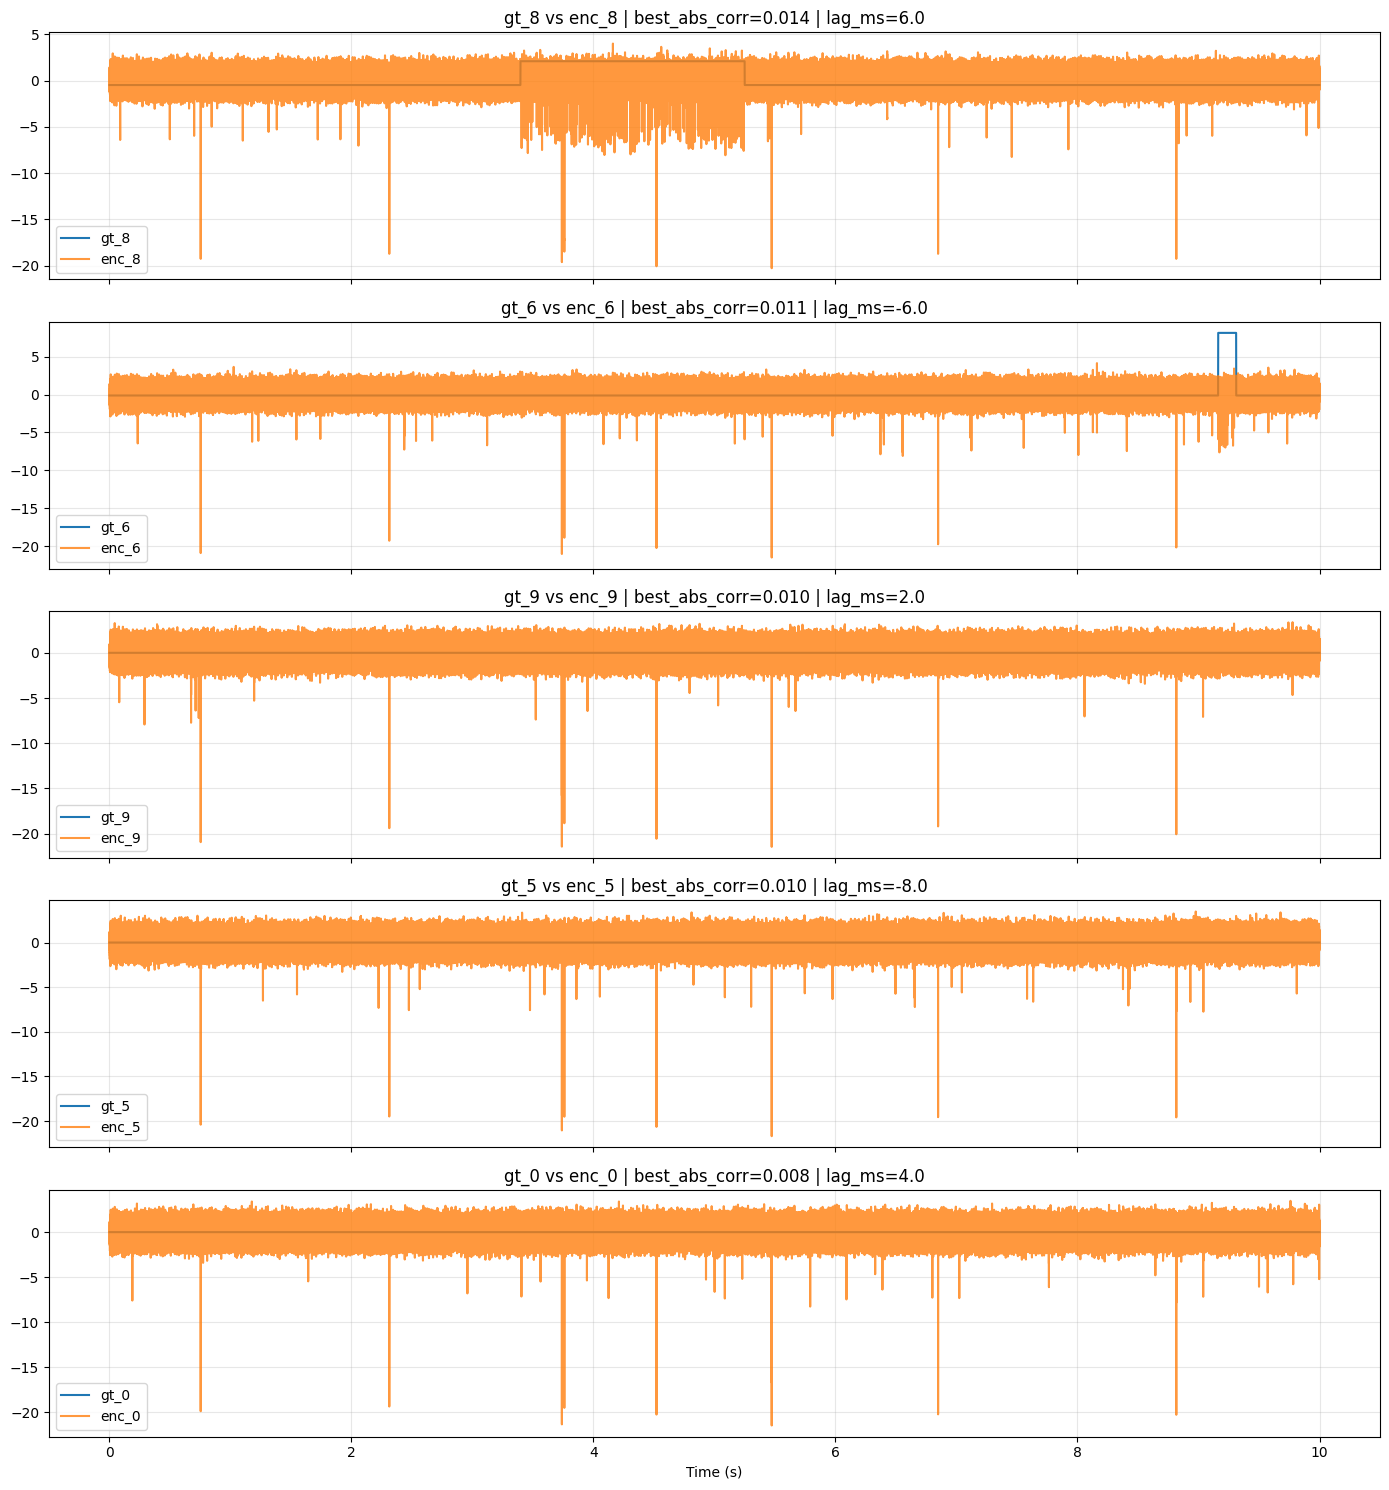


=== Best overlays: smoke_Ani_seed2.h5 ===


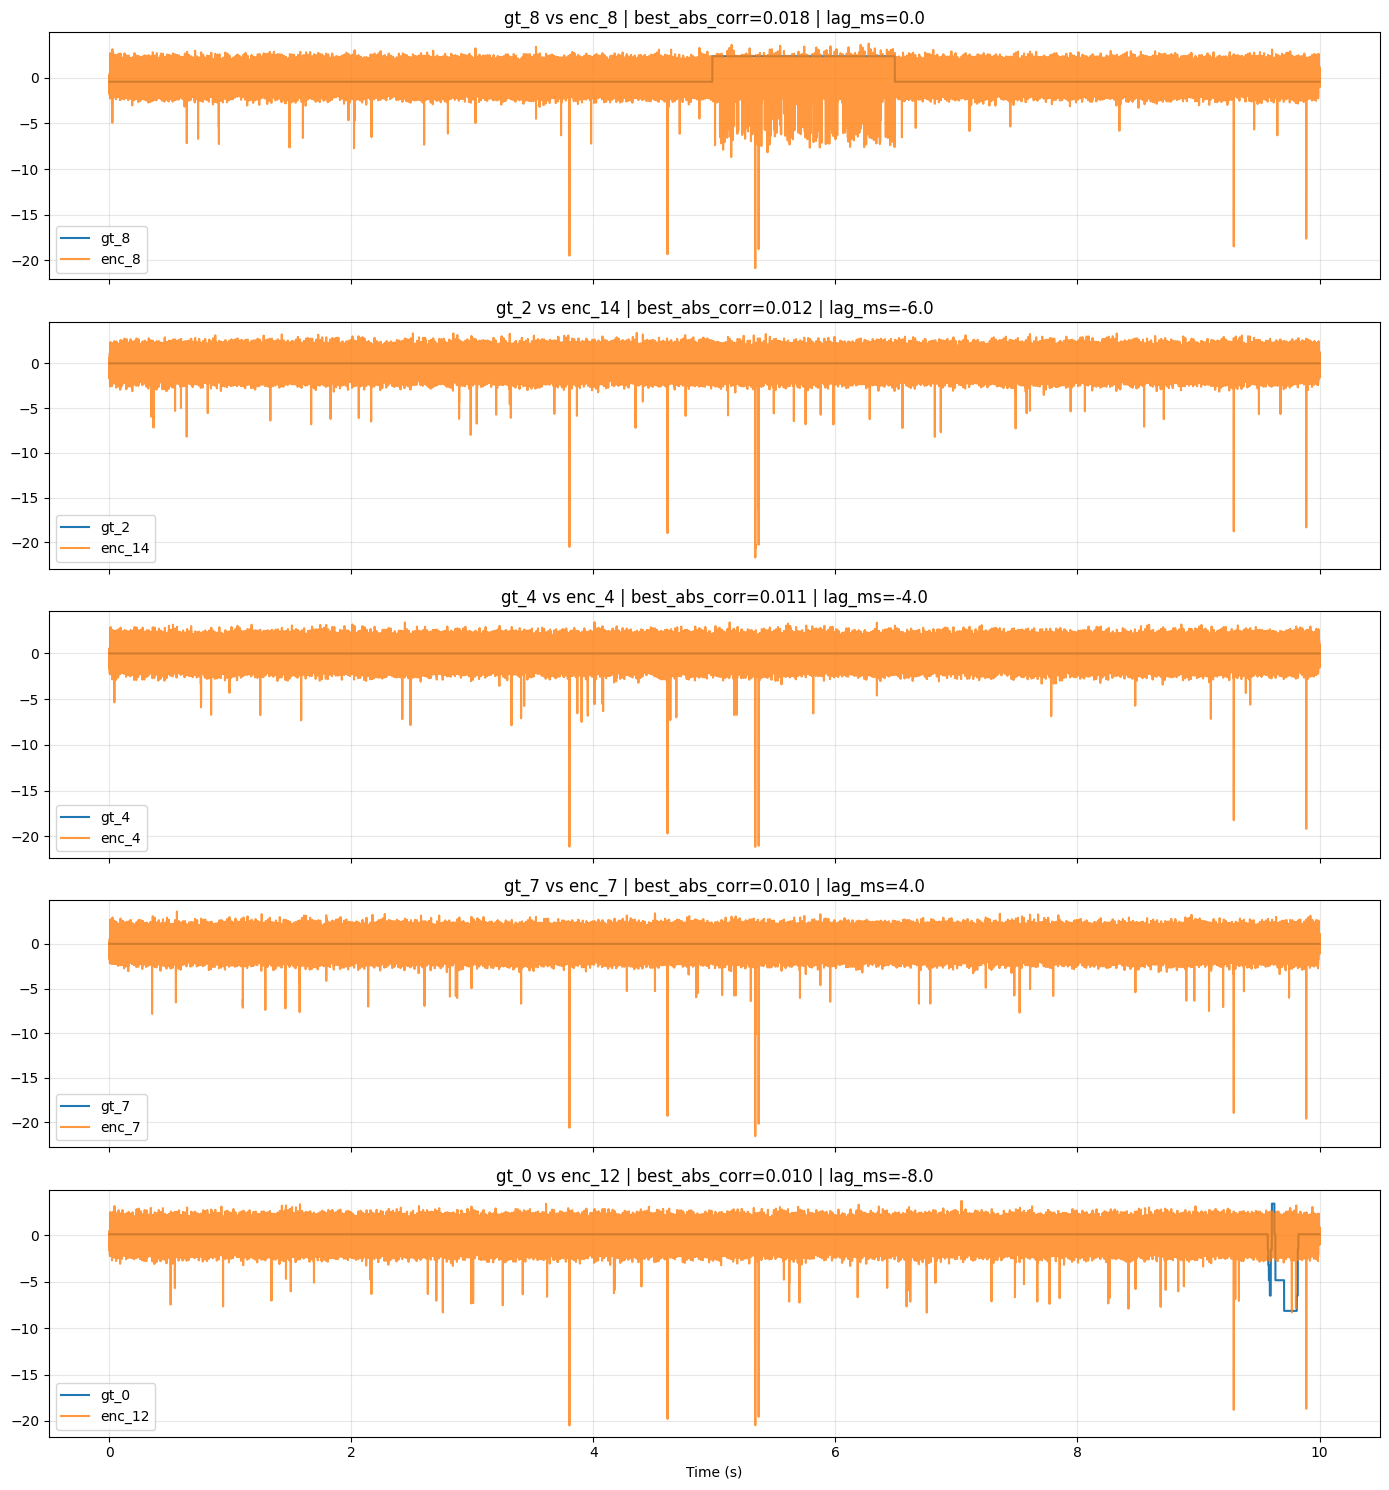


=== Best overlays: smoke_Ani_seed3.h5 ===


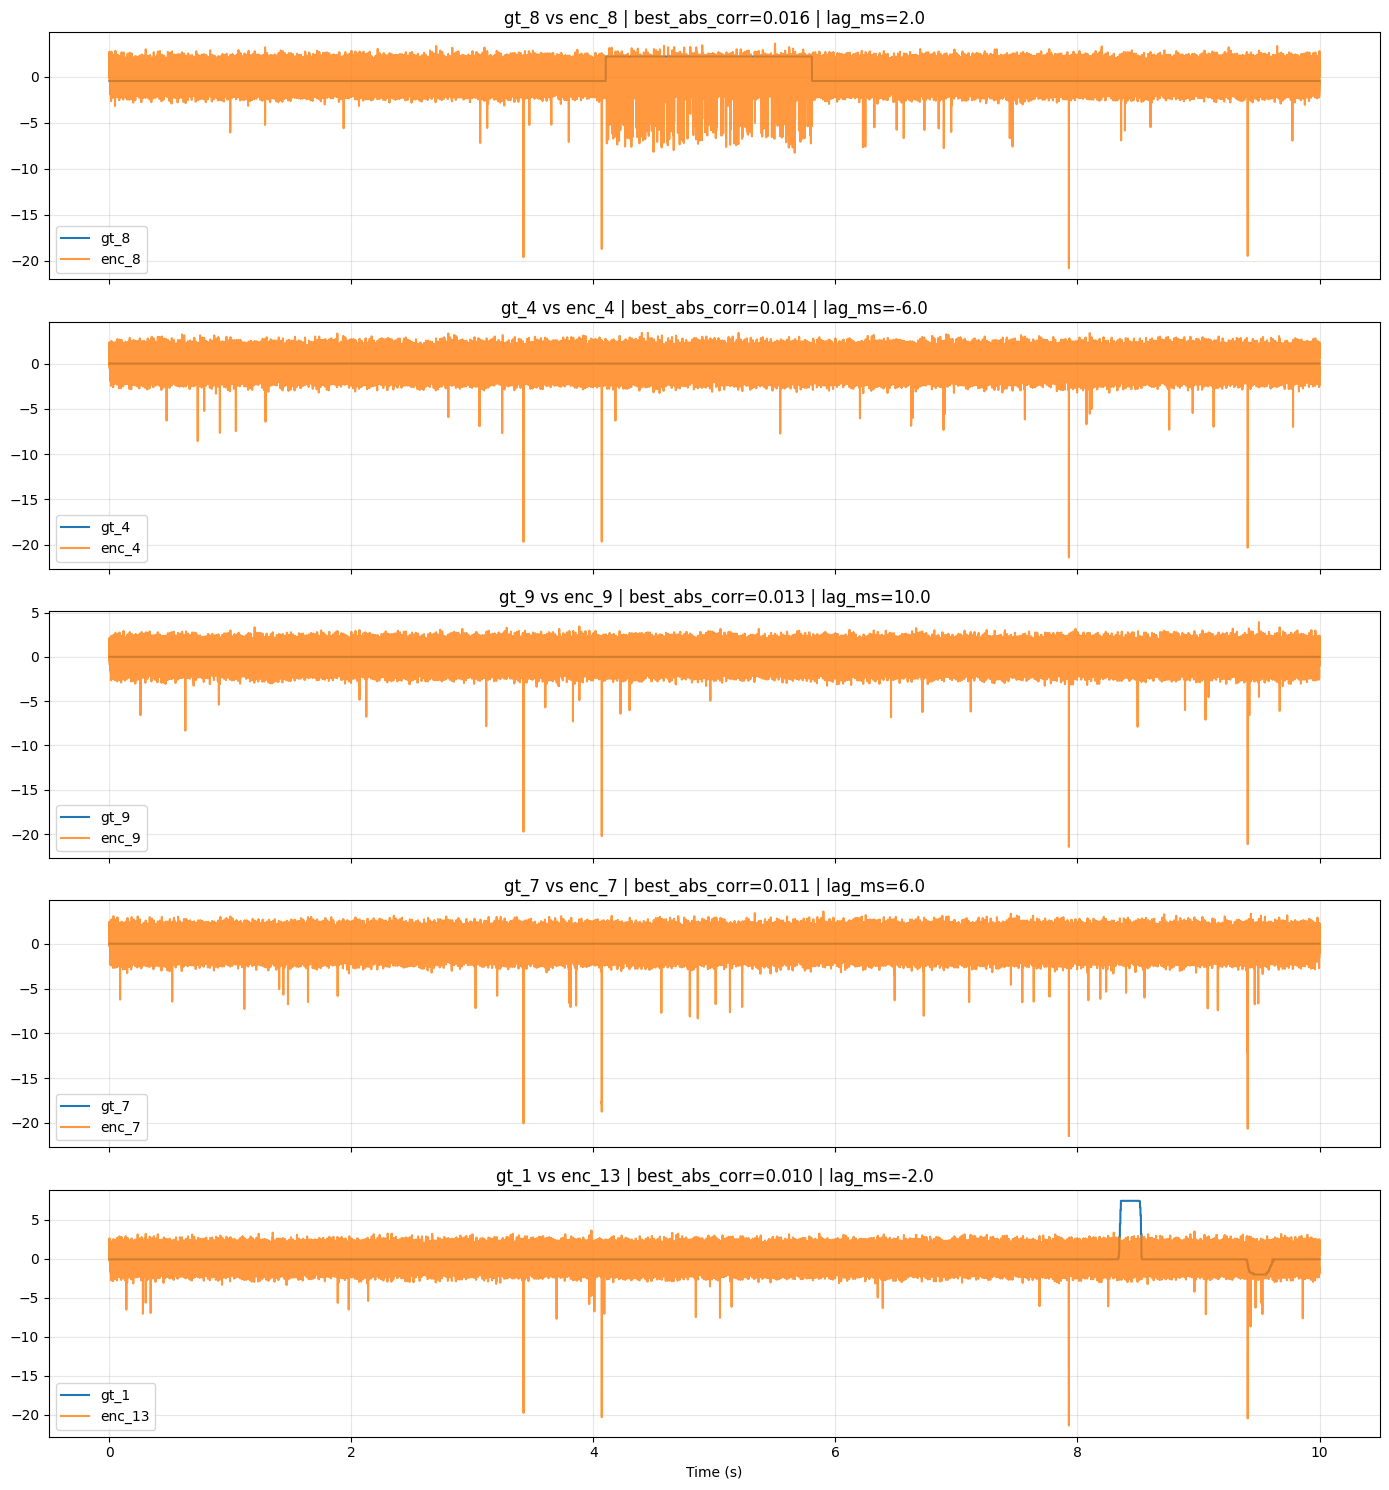


=== Best overlays: smoke_Ani_seed4.h5 ===


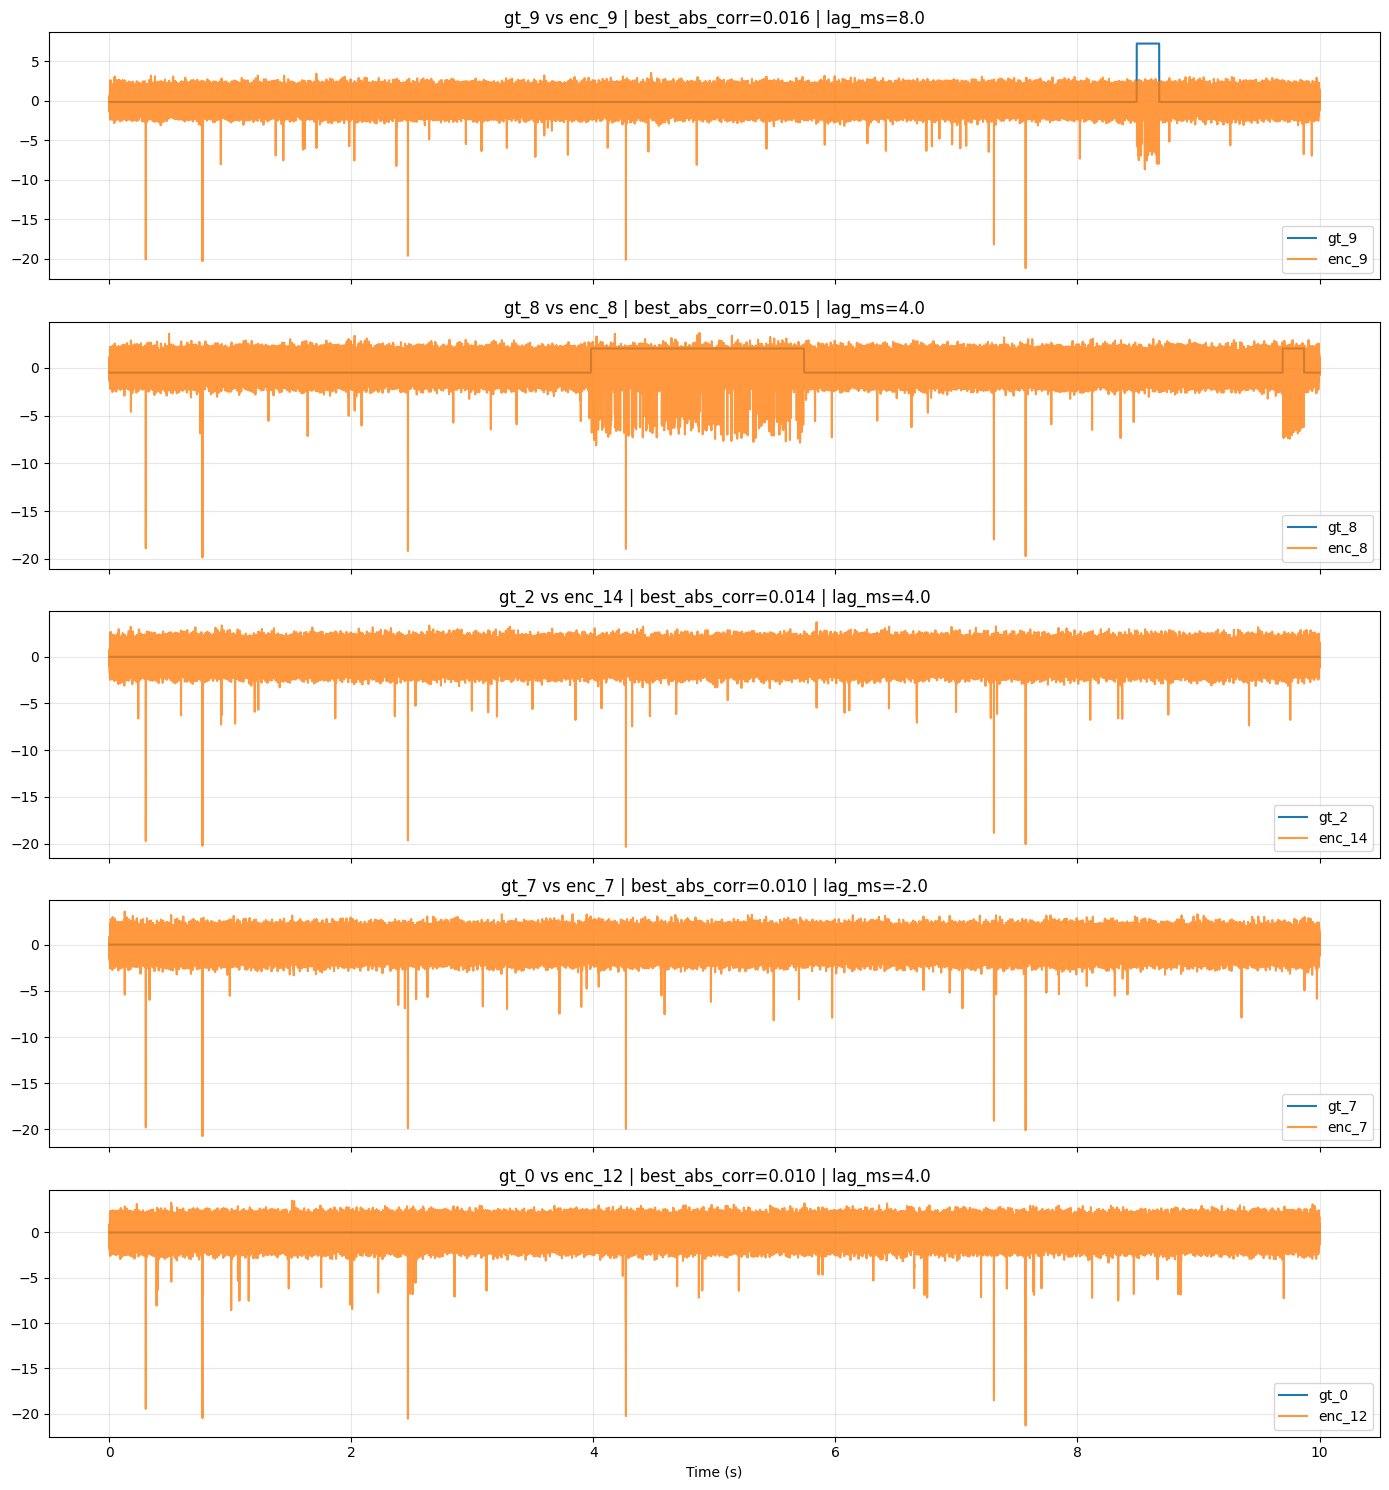


=== Best overlays: smoke_Ani_seed5.h5 ===


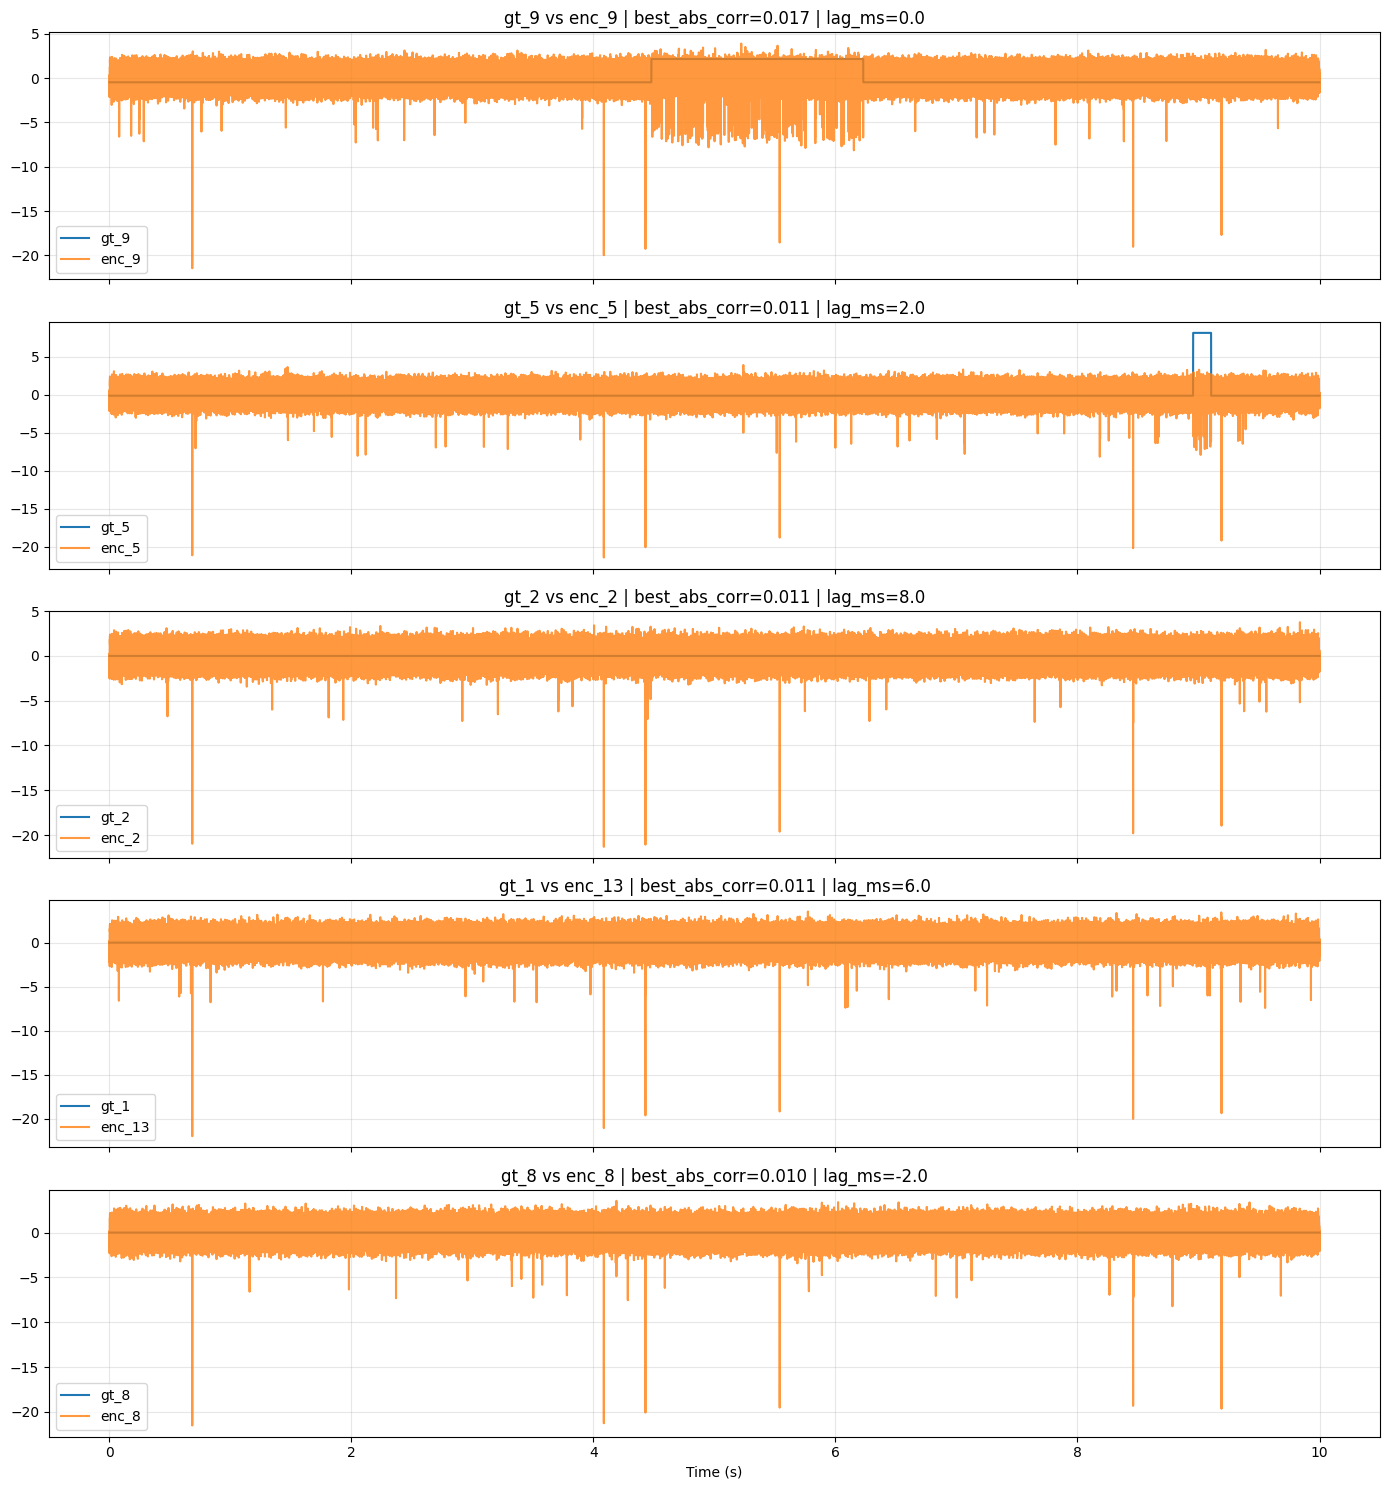

In [14]:
def plot_best_overlays(X: np.ndarray, Y: np.ndarray, lag_df: pd.DataFrame, fs: int, start_sec: float = 0.0, seconds: float = 10.0):
    start = int(start_sec * fs)
    end = min(len(X), int((start_sec + seconds) * fs))

    top_rows = lag_df.sort_values("best_abs_corr", ascending=False).head(5)

    fig, axes = plt.subplots(len(top_rows), 1, figsize=(14, 3 * len(top_rows)), sharex=True)
    if len(top_rows) == 1:
        axes = [axes]

    t = np.arange(start, end) / fs

    for ax, (_, row) in zip(axes, top_rows.iterrows()):
        gt_ch = int(row["gt_channel"])
        enc_ch = int(row["best_enc_channel"])

        y = Y[start:end, gt_ch]
        x = X[start:end, enc_ch]

        # z-score for visual comparability
        yz = (y - y.mean()) / (y.std() + 1e-8)
        xz = (x - x.mean()) / (x.std() + 1e-8)

        ax.plot(t, yz, label=f"gt_{gt_ch}")
        ax.plot(t, xz, label=f"enc_{enc_ch}", alpha=0.8)
        ax.set_title(f"gt_{gt_ch} vs enc_{enc_ch} | best_abs_corr={row['best_abs_corr']:.3f} | lag_ms={row['lag_ms']:.1f}")
        ax.grid(True, alpha=0.3)
        ax.legend()

    axes[-1].set_xlabel("Time (s)")
    plt.tight_layout()
    plt.show()

for path, data in all_data:
    X, Y = split_channels(data)
    lag_df = best_corr_and_lag(X, Y, FS, downsample=64, max_lag_ms=500)
    print(f"\n=== Best overlays: {os.path.basename(path)} ===")
    plot_best_overlays(X, Y, lag_df, FS, start_sec=0, seconds=10)


=== PSD Ground truths: smoke_Ani_seed1.h5 ===


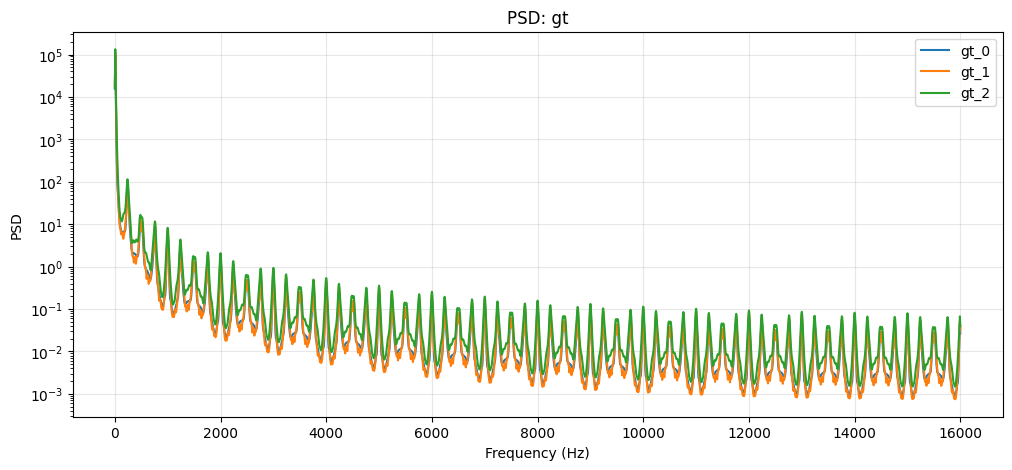


=== PSD Encoded: smoke_Ani_seed1.h5 ===


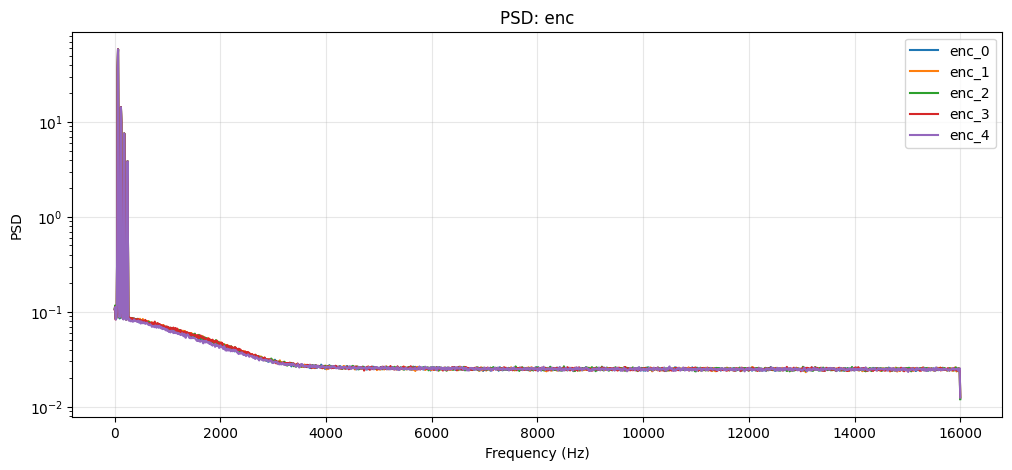


=== PSD Ground truths: smoke_Ani_seed2.h5 ===


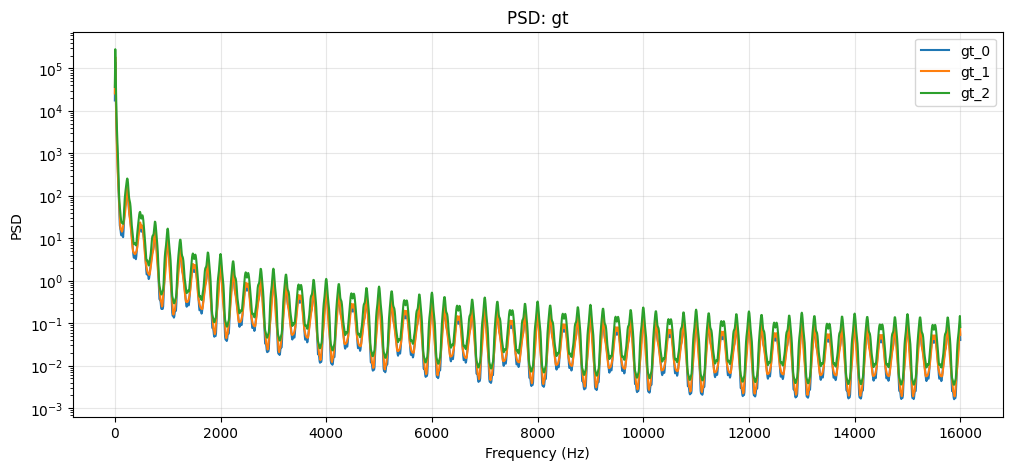


=== PSD Encoded: smoke_Ani_seed2.h5 ===


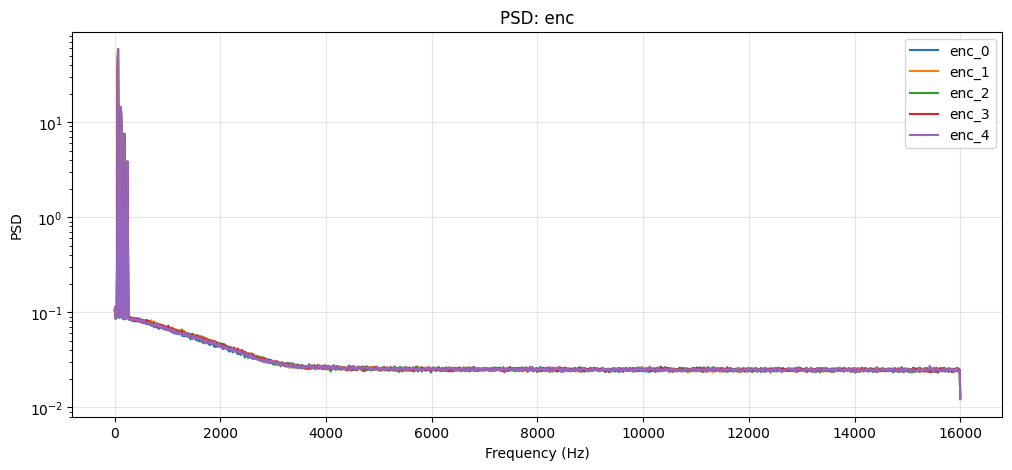


=== PSD Ground truths: smoke_Ani_seed3.h5 ===


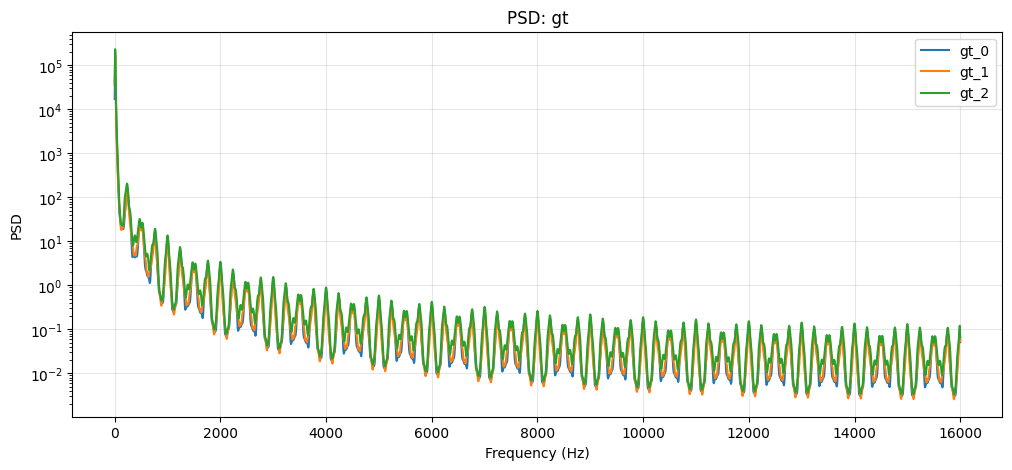


=== PSD Encoded: smoke_Ani_seed3.h5 ===


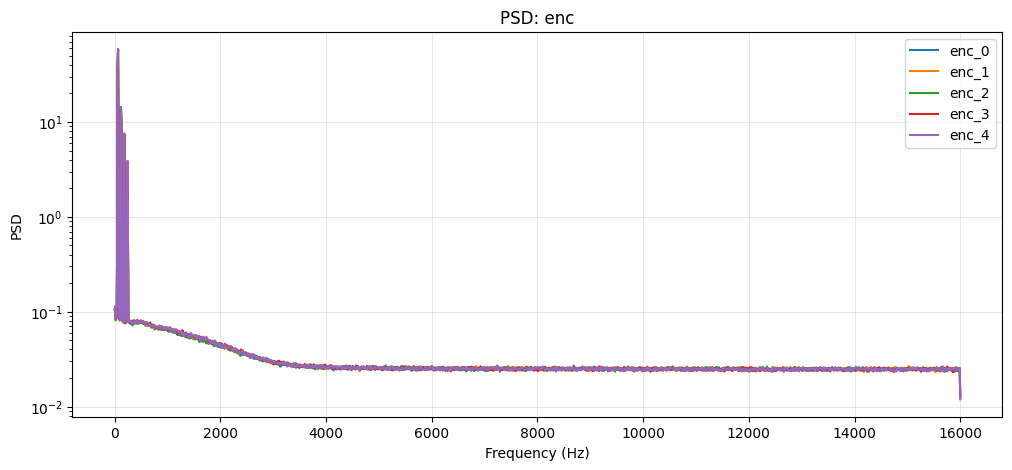


=== PSD Ground truths: smoke_Ani_seed4.h5 ===


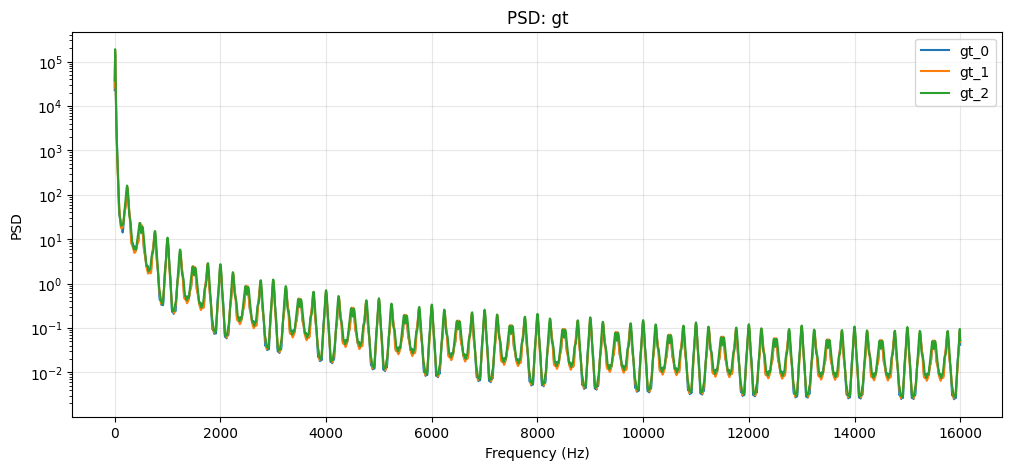


=== PSD Encoded: smoke_Ani_seed4.h5 ===


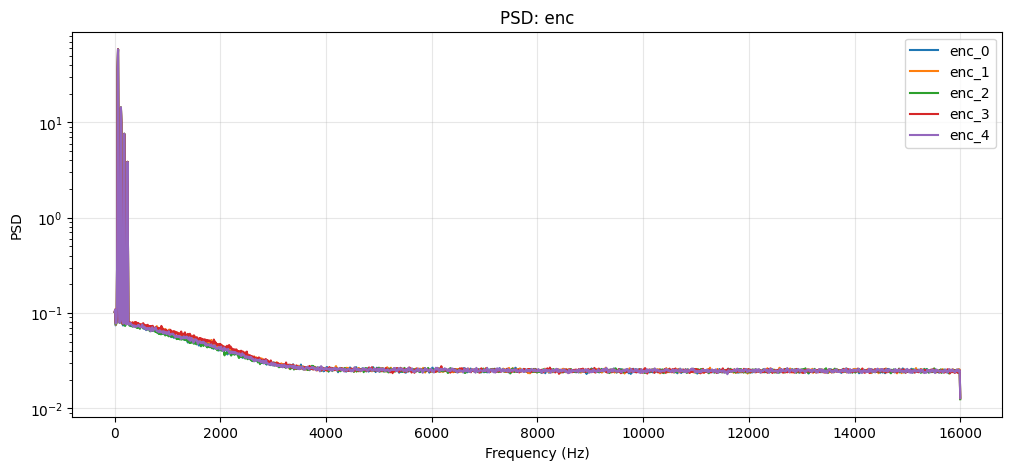


=== PSD Ground truths: smoke_Ani_seed5.h5 ===


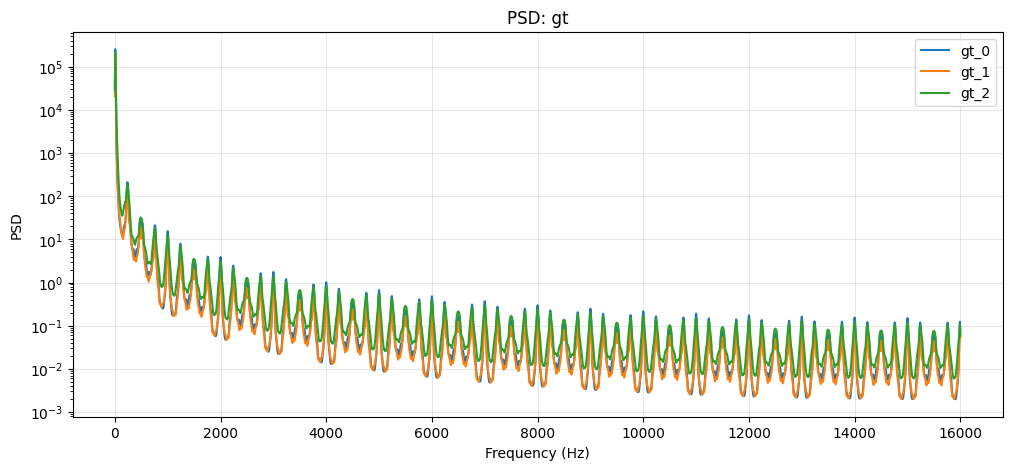


=== PSD Encoded: smoke_Ani_seed5.h5 ===


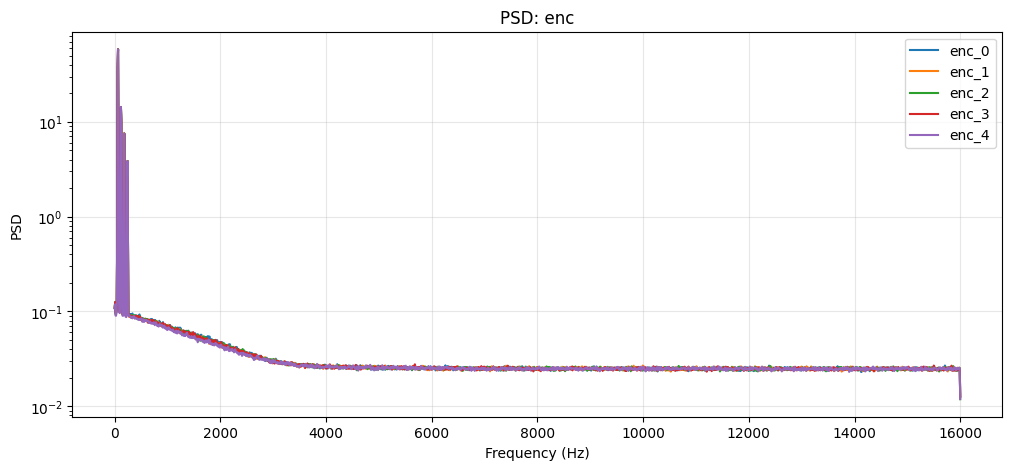

In [15]:
def plot_psd_channels(arr: np.ndarray, fs: int, channels, title_prefix: str, nperseg: int = 4096):
    plt.figure(figsize=(12, 5))
    for ch in channels:
        f, pxx = signal.welch(arr[:, ch], fs=fs, nperseg=nperseg)
        plt.semilogy(f, pxx, label=f"{title_prefix}_{ch}")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("PSD")
    plt.title(f"PSD: {title_prefix}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

for path, data in all_data:
    X, Y = split_channels(data)
    print(f"\n=== PSD Ground truths: {os.path.basename(path)} ===")
    plot_psd_channels(Y, FS, channels=[0, 1, 2], title_prefix="gt")
    print(f"\n=== PSD Encoded: {os.path.basename(path)} ===")
    plot_psd_channels(X, FS, channels=[0, 1, 2, 3, 4], title_prefix="enc")


=== PSD Ground truths: smoke_Ani_seed1.h5 ===


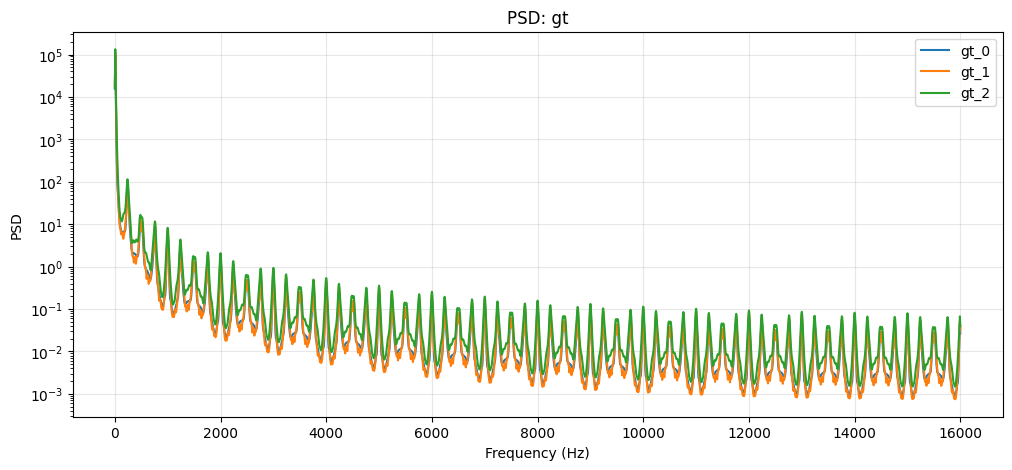


=== PSD Encoded: smoke_Ani_seed1.h5 ===


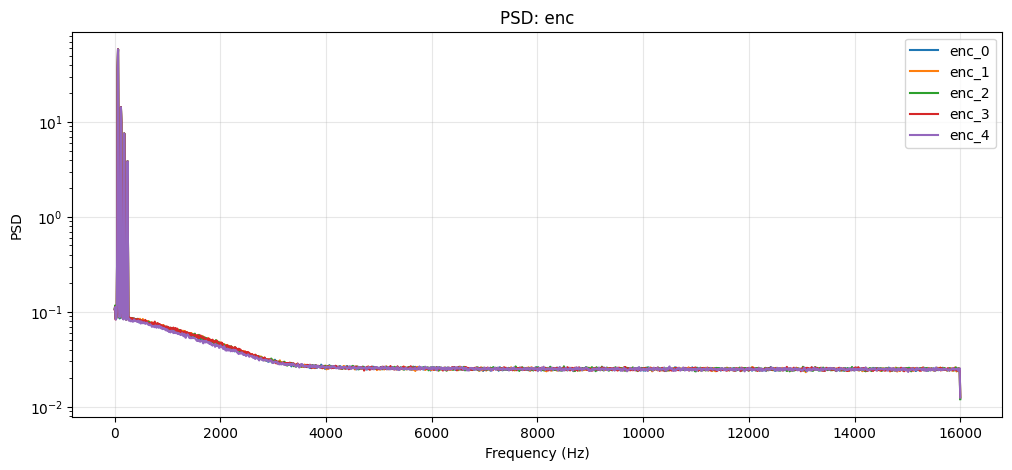


=== PSD Ground truths: smoke_Ani_seed2.h5 ===


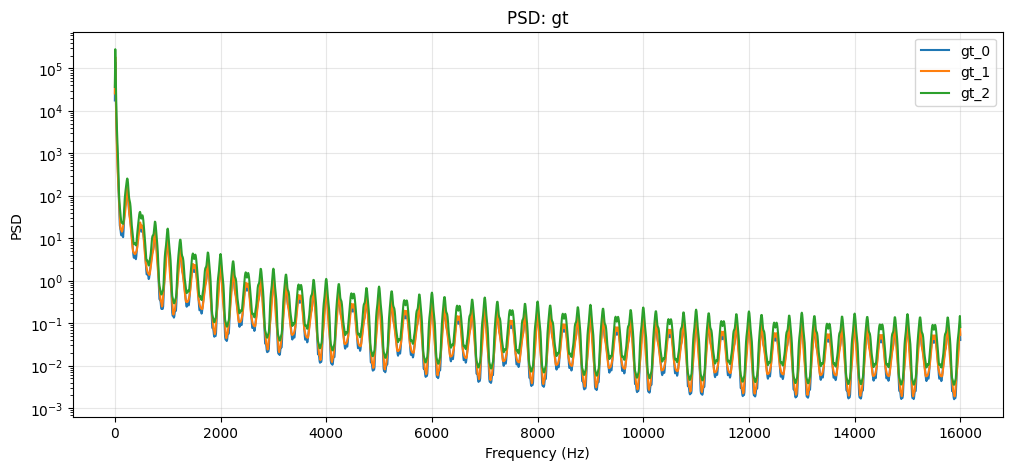


=== PSD Encoded: smoke_Ani_seed2.h5 ===


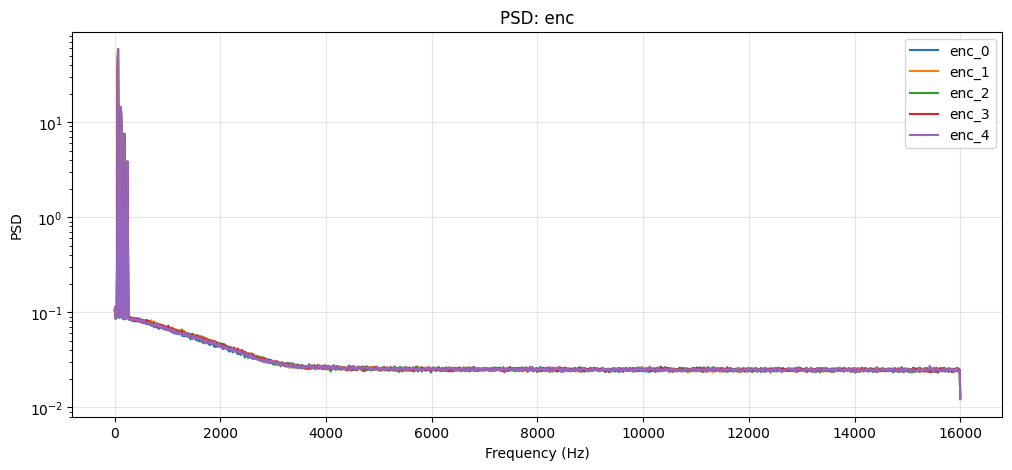


=== PSD Ground truths: smoke_Ani_seed3.h5 ===


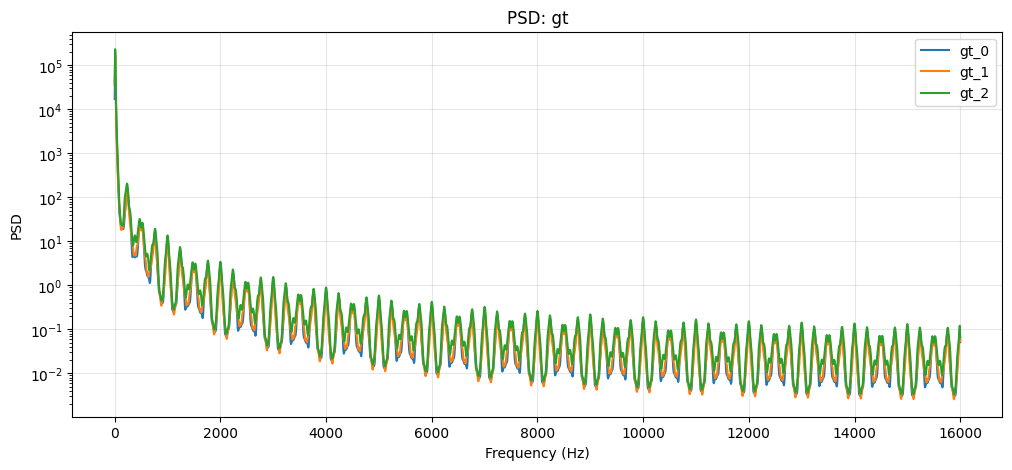


=== PSD Encoded: smoke_Ani_seed3.h5 ===


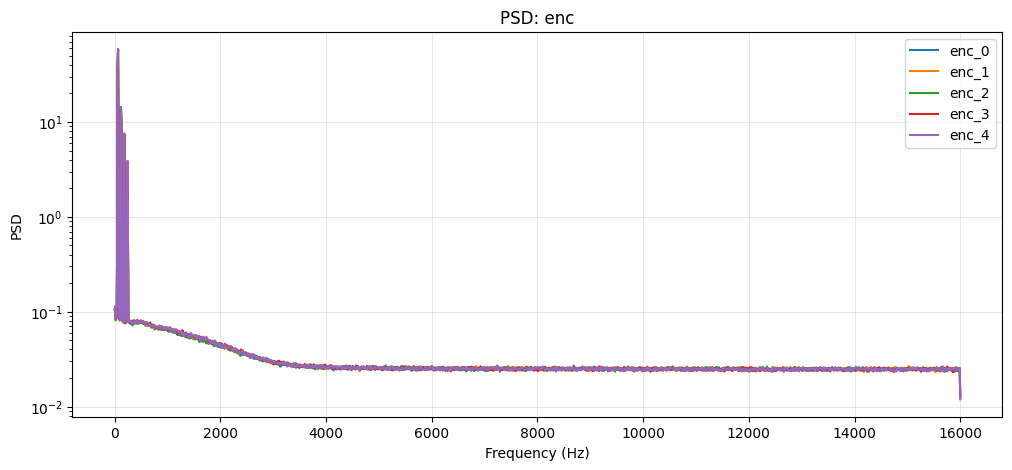


=== PSD Ground truths: smoke_Ani_seed4.h5 ===


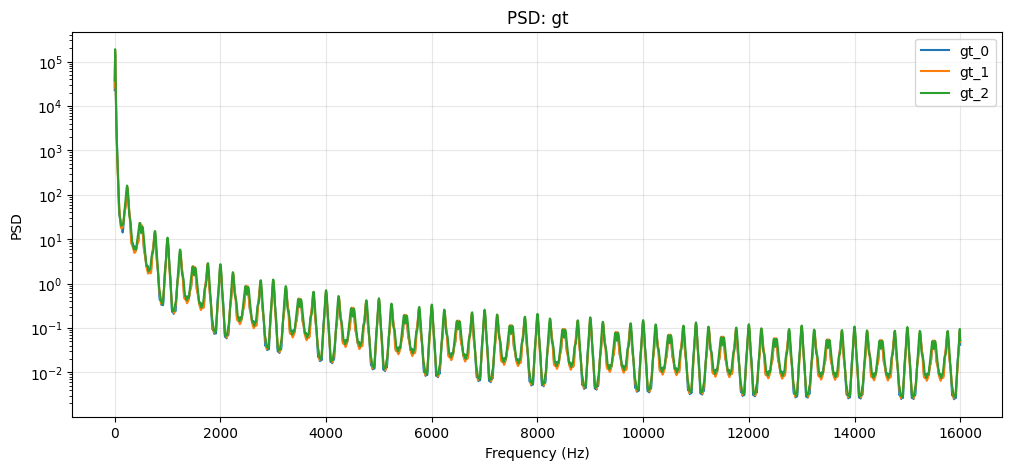


=== PSD Encoded: smoke_Ani_seed4.h5 ===


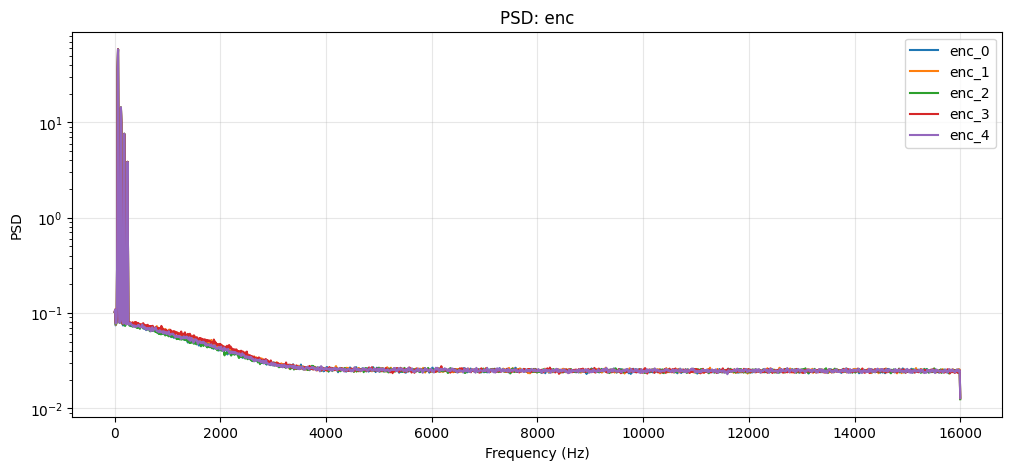


=== PSD Ground truths: smoke_Ani_seed5.h5 ===


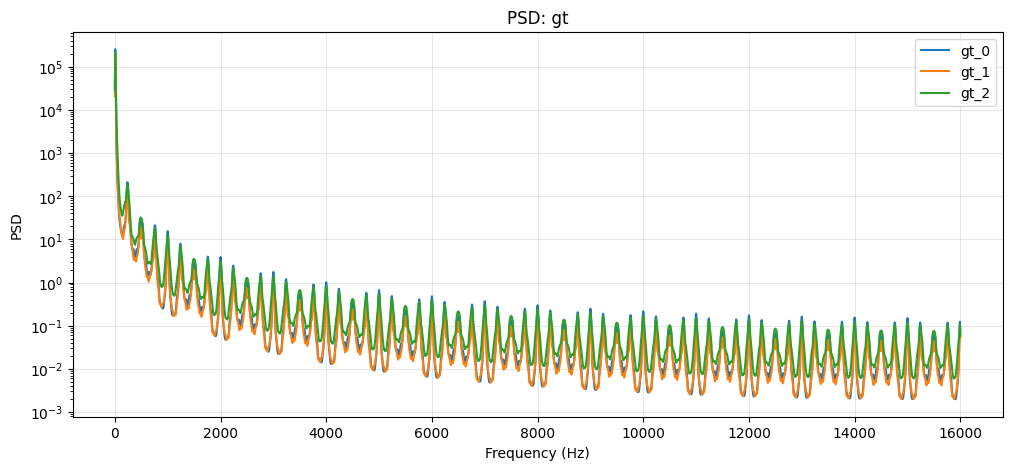


=== PSD Encoded: smoke_Ani_seed5.h5 ===


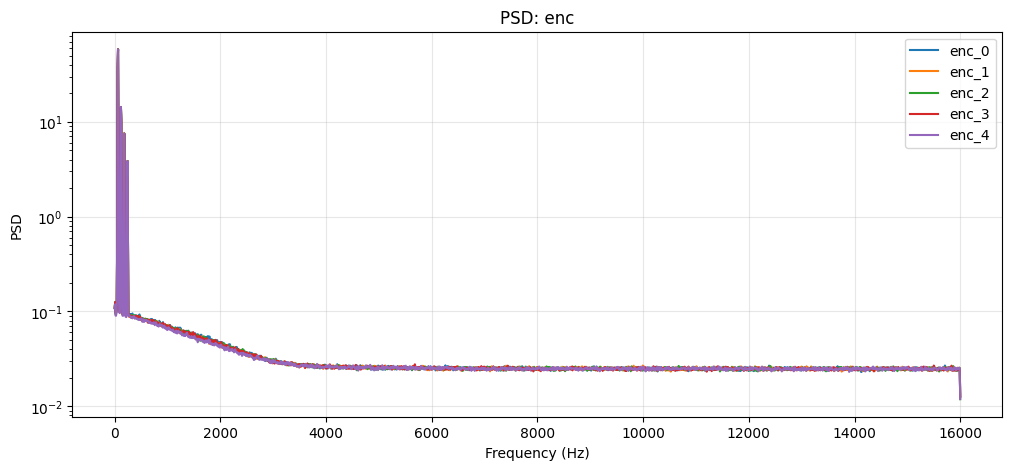

In [16]:
def plot_psd_channels(arr: np.ndarray, fs: int, channels, title_prefix: str, nperseg: int = 4096):
    plt.figure(figsize=(12, 5))
    for ch in channels:
        f, pxx = signal.welch(arr[:, ch], fs=fs, nperseg=nperseg)
        plt.semilogy(f, pxx, label=f"{title_prefix}_{ch}")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("PSD")
    plt.title(f"PSD: {title_prefix}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

for path, data in all_data:
    X, Y = split_channels(data)
    print(f"\n=== PSD Ground truths: {os.path.basename(path)} ===")
    plot_psd_channels(Y, FS, channels=[0, 1, 2], title_prefix="gt")
    print(f"\n=== PSD Encoded: {os.path.basename(path)} ===")
    plot_psd_channels(X, FS, channels=[0, 1, 2, 3, 4], title_prefix="enc")

In [17]:
def time_split(X: np.ndarray, Y: np.ndarray, train_frac: float = 0.7, val_frac: float = 0.15):
    n = len(X)
    n_train = int(n * train_frac)
    n_val = int(n * val_frac)

    X_train = X[:n_train]
    Y_train = Y[:n_train]

    X_val = X[n_train:n_train + n_val]
    Y_val = Y[n_train:n_train + n_val]

    X_test = X[n_train + n_val:]
    Y_test = Y[n_train + n_val:]

    return X_train, Y_train, X_val, Y_val, X_test, Y_test

In [ ]:
def is_binaryish_channel(y: np.ndarray, max_unique: int = 4):
    uniq = np.unique(y[: min(len(y), 200000)])
    return len(uniq) <= max_unique

def run_simple_baseline(X: np.ndarray, Y: np.ndarray):
    X_train, Y_train, X_val, Y_val, X_test, Y_test = time_split(X, Y)

    rows = []

    for ch in range(Y.shape[1]):
        y_train = Y_train[:, ch]
        y_val = Y_val[:, ch]
        y_test = Y_test[:, ch]

        if is_binaryish_channel(Y[:, ch]):
            # Map to {0,1} if needed
            uniq = np.unique(y_train)
            uniq_sorted = np.sort(uniq)

            if len(uniq_sorted) == 1:
                rows.append({
                    "gt_channel": ch,
                    "task": "binary",
                    "note": "constant channel, skipped"
                })
                continue

            lo = uniq_sorted[0]
            hi = uniq_sorted[-1]

            y_train_bin = (y_train > (lo + hi) / 2).astype(int)
            y_val_bin = (y_val > (lo + hi) / 2).astype(int)
            y_test_bin = (y_test > (lo + hi) / 2).astype(int)

            clf = Pipeline([
                ("scaler", StandardScaler()),
                ("model", LogisticRegression(max_iter=1000))
            ])
            clf.fit(X_train, y_train_bin)

            val_prob = clf.predict_proba(X_val)[:, 1]
            val_pred = (val_prob >= 0.5).astype(int)

            test_prob = clf.predict_proba(X_test)[:, 1]
            test_pred = (test_prob >= 0.5).astype(int)

            row = {
                "gt_channel": ch,
                "task": "binary",
                "val_acc": accuracy_score(y_val_bin, val_pred),
                "val_f1": f1_score(y_val_bin, val_pred, zero_division=0),
                "val_auc": roc_auc_score(y_val_bin, val_prob) if len(np.unique(y_val_bin)) > 1 else np.nan,
                "test_acc": accuracy_score(y_test_bin, test_pred),
                "test_f1": f1_score(y_test_bin, test_pred, zero_division=0),
                "test_auc": roc_auc_score(y_test_bin, test_prob) if len(np.unique(y_test_bin)) > 1 else np.nan,
            }
            rows.append(row)

        else:
            reg = Pipeline([
                ("scaler", StandardScaler()),
                ("model", Ridge(alpha=1.0))
            ])
            reg.fit(X_train, y_train)

            val_pred = reg.predict(X_val)
            test_pred = reg.predict(X_test)

            def safe_corr(a, b):
                if np.std(a) < 1e-8 or np.std(b) < 1e-8:
                    return np.nan
                return pearsonr(a, b)[0]

            row = {
                "gt_channel": ch,
                "task": "continuous",
                "val_r2": r2_score(y_val, val_pred),
                "val_corr": safe_corr(y_val, val_pred),
                "val_mse": mean_squared_error(y_val, val_pred),
                "test_r2": r2_score(y_test, test_pred),
                "test_corr": safe_corr(y_test, test_pred),
                "test_mse": mean_squared_error(y_test, test_pred),
            }
            rows.append(row)

    return pd.DataFrame(rows)

for path, data in all_data:
    X, Y = split_channels(data)
    print(f"\n=== Simple baseline: {os.path.basename(path)} ===")
    baseline_df = run_simple_baseline(X, Y)
    display(baseline_df)


=== Simple baseline: smoke_Ani_seed1.h5 ===


In [ ]:
def make_windowed_features(X: np.ndarray, Y: np.ndarray, window_size: int, stride: int = 1):
    """
    X: (T, C)
    Y: (T, K)
    Returns:
      Xw: (N, window_size*C)
      Yw: (N, K) aligned to the last timepoint in each window
    """
    feats = []
    targets = []
    for t in range(window_size - 1, len(X), stride):
        window = X[t - window_size + 1:t + 1]
        feats.append(window.reshape(-1))
        targets.append(Y[t])
    return np.asarray(feats), np.asarray(targets)

def run_windowed_baseline(X: np.ndarray, Y: np.ndarray, fs: int, window_ms: float = 100.0, stride: int = 1):
    window_size = max(1, int(round(window_ms * fs / 1000.0)))
    print(f"Using window_ms={window_ms}, window_size={window_size} samples")

    Xw, Yw = make_windowed_features(X, Y, window_size, stride=stride)
    return run_simple_baseline(Xw, Yw)

for path, data in all_data:
    X, Y = split_channels(data)

    # You can try 10 ms first if 100 ms is too huge at 32 kHz
    X_ds = X
    Y_ds = Y

    # Strongly recommended: downsample before windowing
    DS = 64
    usable = (len(X_ds) // DS) * DS
    X_ds = X_ds[:usable].reshape(-1, DS, X.shape[1]).mean(axis=1)
    Y_ds = Y_ds[:usable].reshape(-1, DS, Y.shape[1]).mean(axis=1)
    fs_ds = FS / DS

    print(f"\n=== Windowed baseline: {os.path.basename(path)} ===")
    windowed_df = run_windowed_baseline(X_ds, Y_ds, fs=int(fs_ds), window_ms=100.0, stride=1)
    display(windowed_df)

In [ ]:
rows = []
for path, data in all_data:
    duration_sec = len(data) / FS
    rows.append({
        "file": os.path.basename(path),
        "n_samples": len(data),
        "n_channels": data.shape[1],
        "duration_sec": duration_sec,
        "duration_min": duration_sec / 60.0,
    })
display(pd.DataFrame(rows))

In [ ]:
OUT_DIR = "/content/decoder_exploration_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

for path, data in all_data:
    stem = os.path.splitext(os.path.basename(path))[0]
    X, Y = split_channels(data)

    summarize_channels(X, "enc_").to_csv(os.path.join(OUT_DIR, f"{stem}_encoded_summary.csv"), index=False)
    summarize_channels(Y, "gt_").to_csv(os.path.join(OUT_DIR, f"{stem}_gt_summary.csv"), index=False)

    lag_df = best_corr_and_lag(X, Y, FS, downsample=64, max_lag_ms=500)
    lag_df.to_csv(os.path.join(OUT_DIR, f"{stem}_best_corr_lag.csv"), index=False)

    baseline_df = run_simple_baseline(X, Y)
    baseline_df.to_csv(os.path.join(OUT_DIR, f"{stem}_baseline_current_sample.csv"), index=False)

    DS = 64
    usable = (len(X) // DS) * DS
    X_ds = X[:usable].reshape(-1, DS, X.shape[1]).mean(axis=1)
    Y_ds = Y[:usable].reshape(-1, DS, Y.shape[1]).mean(axis=1)
    fs_ds = int(FS / DS)

    windowed_df = run_windowed_baseline(X_ds, Y_ds, fs=fs_ds, window_ms=100.0, stride=1)
    windowed_df.to_csv(os.path.join(OUT_DIR, f"{stem}_baseline_windowed_100ms.csv"), index=False)

print("Saved CSVs to:", OUT_DIR)
print(os.listdir(OUT_DIR))